In [1]:
import random
import os
import sys
from pathlib import Path
from collections import Counter

project_root = None
for candidate in [Path.cwd().resolve()] + list(Path.cwd().resolve().parents):
    if (candidate / "GetData.py").exists() and (candidate / "ToIPA.py").exists():
        project_root = candidate
        break

if project_root is None:
    raise RuntimeError("Project root was not found. Open the notebook from inside Thesis_project_final or its subfolders.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

from GetData import load_selected_embeddings
from ToIPA import corpres_to_ipa_symbol, panphon_features
from PhoneticFeatures_Training.phonetic_feature_utils import (
    FEATURE_NAMES,
    PhonemeEmbeddingDataset,
    PhonemeFeaturePredictor,
    build_prediction_rows,
    build_resistance_bias_dict,
    collect_symbol_prediction_stats,
    compute_class_weights,
    compute_confusion_matrices,
    evaluate_before_training,
    infer_num_classes,
    inspect_single_prediction,
    plot_confusion_matrices,
    plot_confusion_matrices_norm,
    plot_feature_accuracy,
    plot_symbol_prediction_distributions,
    plot_training,
    train_model,
    compute_balanced_accuracy
)


In [2]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA devices: {torch.cuda.device_count()}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA runtime version: {torch.version.cuda}")
print(f"cuDNN version: {torch.backends.cudnn.version() if torch.cuda.is_available() else 'N/A'}")

# Проверь установку PyTorch
print(f"torch.cuda.is_built(): {torch.backends.cudnn.enabled}")



CUDA available: True
CUDA devices: 1
PyTorch version: 1.10.2+cu111
CUDA runtime version: 11.1
cuDNN version: 8005
torch.cuda.is_built(): True


In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Cleaned copy
Эта копия вычищает нестабильные части пайплайна: обучение, confusion matrices и блок пост-анализа предсказаний.


In [4]:
root_dir = r'\\nid-tts-01\mnt\hot_store\trainee_common\ananeva\CORPRES_embs_no_averaging'
save_path = r'C:\Users\ext-ananeva\phon_clust\gitlab\ssl_phoneme_clusterizer\Main_project'
speakers = ['Vladimir', 'Maria', 'Mikhail', 'Anna', 'Galina', 'Victoria', 'Petr', 'Alexander']
phonetic_features = ['syl', 'son', 'cons', 'cont', 'delrel', 'lat', 'nas', 'strid', 'voi', 'sg', 'cg', 'ant', 'cor', 'distr', 'lab', 'hi', 'lo', 'back', 'round', 'velaric', 'tense', 'long']
phoneme_list_full = ['a0', 'a1', 'a2', 'a4', 'b', "b'", 'c', 'ch', 'ch_', 'd', "d'", 'e0', 'e1', 'e2', 'e4', 'f', "f'", 'g', "g'", 'h', "h'", 'i0', 'i1', 'i2', 'i4', 'j', 'jr', 'jl', 'ji4', 'k', "k'", 'l', "l'", 'm', "m'", 'n', "n'", 'o0', 'o1', 'o2', 'o4', 'p', "p'", 'r', "r'", 's', "s'", 'sc', 'sh', 't', "t'", 'u0', 'u1', 'u2', 'u4', 'v', "v'", 'y0', 'y1', 'y2', 'y4', 'z', "z'", 'zh', "zh'", 'C', 'CH', 'H', 'SC']

In [5]:
debugging = False
save_exp = False
training = True
select_embeddings = False # выбирать эмбеддинги из корпуса или подгрузить из файлов

resistant_bias = True

ignore_third_calss = False
ce_ignore_index = 2 if ignore_third_calss else -100
mertric_ignore_index = 2 if ignore_third_calss else None

if resistant_bias: 
    if ignore_third_calss:
        model_name = 'ResistantBias_2class_do'
    else:
        model_name = 'ResistantBias_3class_do'
else:
    if ignore_third_calss:
        model_name = 'NoResistantBias_2class_do'
    else:
        model_name = 'NoResistantBias_3class_do'
    

#model_id = 'VACXUXVEXO'
training_mode = 'triplet' # ['triplet', 'ctc', 'averaged']
phoneme_list = ['a0', 'a4', 'b', "b'", 'c', 'ch', 'd', "d'", 'e0', 'f', "f'", 'g', 'h', 'i0','i4', 'j', 'k', "k'", 'l', "l'", 'm', "m'", 'n', "n'", 'o0', 'p', "p'", 'r', "r'", 's', "s'", 'sh', 't', "t'", 'u0', 'v', "v'", 'y0', 'z', "z'", 'zh', 'a1', 'i1','u1', 'y1', ]
# phoneme_list = ['a0', 'a4', 'b', 'd','e0', 'f',  'g', 'h', 'i0','i4', 'j', 'k','l', 'm',  'n', 'o0', 'p', 'r', 's', 'sh', 't', 'u0', 'v',  'y0', 'z', 'zh', 'sil']
# phoneme_list = ['a0', 't', "i0", "t'", "k", 's', "s'" ]  
# интересующие фонемы (без позиций)
samples_of_ph = 1000              # сколько примеров на фонему
train_speakers = ['Vladimir', 'Maria', 'Mikhail', 'Anna']
test_speakers = ['Galina', 'Victoria', 'Petr', 'Alexander']

if debugging:
    phoneme_list = ['a0', 't', "i0" ]  
    samples_of_ph = 1            
    train_speakers = ['Vladimir']
    test_speakers = ['Galina']
    

In [6]:
int_code = [random.randint(65, 90) for i in range(10)]
uid = ''.join([chr(code) for code in int_code])

In [7]:
log_path = save_path + '\\runs\\' + uid

In [8]:
num_classes = len(phoneme_list)

In [9]:
learning_rate = 1e-3
weight_decay=1e-4
batch_size = 32
num_epochs = 20
dropout = 0.1
input_size = 512

In [10]:
save_model_path = os.path.join(r'C:\Users\ext-ananeva\phon_clust\gitlab\ssl_phoneme_clusterizer\Main_project\PhoneticFeatures_Training\models', model_name)
save_model_path

'C:\\Users\\ext-ananeva\\phon_clust\\gitlab\\ssl_phoneme_clusterizer\\Main_project\\PhoneticFeatures_Training\\models\\ResistantBias_3class_do'

In [11]:
if select_embeddings:
    train_embeddings, train_phonemes_nobord, _ = load_selected_embeddings(root_dir, phoneme_list, samples_of_ph, train_speakers,  
    tiplet_variation='no borders') 
    test_embeddings, test_phonemes_nobord, _ = load_selected_embeddings(root_dir, phoneme_list, samples_of_ph, test_speakers,  triplet_variation='no borders')
    
else:
    train_embeddings = torch.load("data/train_embeddings.pt")
    test_embeddings = torch.load("data/test_embeddings.pt")

In [12]:
train_dataset = PhonemeEmbeddingDataset(train_embeddings, phoneme_list, corpres_to_ipa_symbol=corpres_to_ipa_symbol, panphon_features=panphon_features)
test_dataset = PhonemeEmbeddingDataset(test_embeddings, phoneme_list, corpres_to_ipa_symbol=corpres_to_ipa_symbol, panphon_features=panphon_features)

In [13]:
train_dataset[-1]

(tensor([ 0.1050, -0.0488,  0.0636, -0.0468,  0.0461, -0.0588, -0.0122, -0.0203,
         -0.0079,  0.0675,  0.0055, -0.0161,  0.0044, -0.0550,  0.0186, -0.0486,
          0.0164, -0.1194,  0.0642, -0.0077, -0.0985,  0.0050,  0.0881, -0.0303,
         -0.0652, -0.0423,  0.0149,  0.1020, -0.0876,  0.0096,  0.0553, -0.0550,
         -0.0842, -0.0408, -0.0789, -0.0361, -0.0695, -0.0629, -0.0341, -0.0502,
          0.0975,  0.1066, -0.0714, -0.0282, -0.0621, -0.0326, -0.0569, -0.0192,
          0.0544,  0.0065,  0.0190,  0.0571, -0.0515, -0.0487, -0.0535,  0.0497,
          0.0038,  0.0537, -0.0307, -0.0644, -0.0770,  0.0983, -0.0095, -0.0189,
          0.0147,  0.0599, -0.0809, -0.0161,  0.0953,  0.0360,  0.1602,  0.0494,
         -0.0508, -0.0274, -0.0304,  0.0692,  0.0620, -0.0832, -0.0203,  0.0206,
          0.0086, -0.0460,  0.0649,  0.0136, -0.0038,  0.0955,  0.1187,  0.0486,
          0.1017, -0.0041,  0.1044,  0.0410, -0.0120, -0.0615,  0.0260, -0.0032,
          0.0369, -0.0072, -

In [14]:
label_counter = Counter()
phoneme_counter = Counter()
ipa_counter = Counter()
feature_sum = None
feature_count = 0

for i in range(len(train_dataset)):
    _, labels, phonemes, ipa_symbols, features = train_dataset[i]

    # если не триплет - приводим всё к списку
    if not train_dataset.triplet_labels:
        labels = [labels.item()]
        phonemes = [phonemes[0]]
        ipa_symbols = [ipa_symbols[0]]
        features = [features] if features is not None else []

    # считаем частоты
    for l in labels:
        label_counter[int(l)] += 1
    for ph in phonemes:
        phoneme_counter[ph] += 1
    for ipa in ipa_symbols:
        ipa_counter[ipa] += 1        

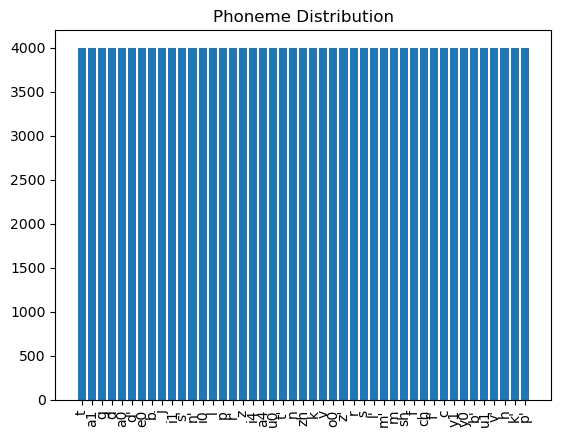

In [15]:
plt.figure()
plt.bar(phoneme_counter.keys(), phoneme_counter.values())
plt.xticks(rotation=90)
plt.title("Phoneme Distribution")
plt.show()

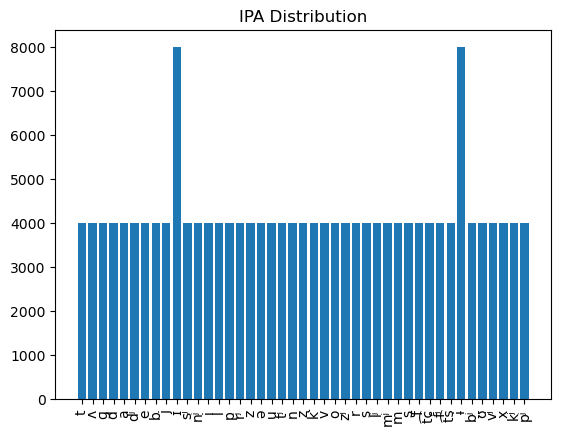

In [16]:
plt.figure()
plt.bar(ipa_counter.keys(), ipa_counter.values())
plt.xticks(rotation=90)
plt.title("IPA Distribution")
plt.show()

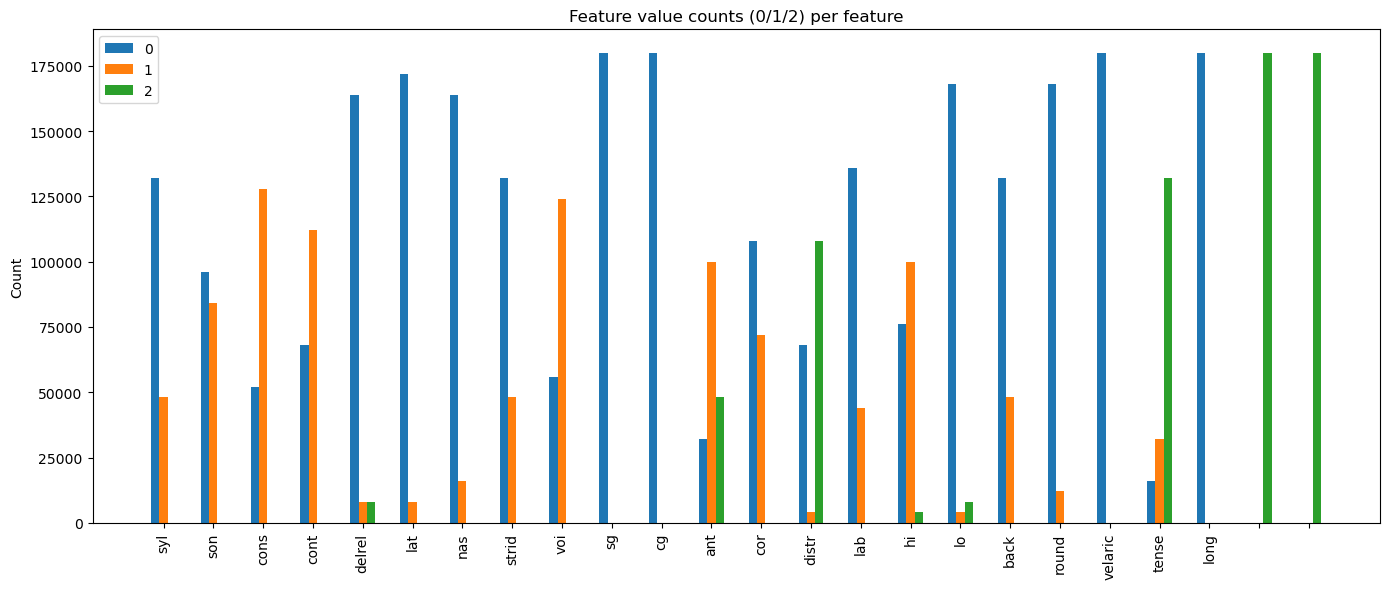

In [17]:
# будем считать: axis=0 — признаки, axis=1 — значение (0,1,2)
feature_counts = None

for i in range(len(train_dataset)):
    _, labels, phonemes, ipa_symbols, features = train_dataset[i]

    if not train_dataset.triplet_labels:
        labels = [labels.item()]
        phonemes = [phonemes[0]]
        ipa_symbols = [ipa_symbols[0]]
        features = [features] if features is not None else []

    for f in features:
        f = f.numpy().astype(int)  # предполагаем значения 0/1/2, форма (num_features,)

        if feature_counts is None:
            # shape: (num_features, 3) — для значений 0,1,2
            feature_counts = np.zeros((len(f), 3), dtype=int)

        # проверим, что все значения в {0,1,2}
        assert ((f >= 0) & (f <= 2)).all()

        for val in (0, 1, 2):
            feature_counts[:, val] += (f == val).astype(int)

# построение сгруппированной гистограммы
if feature_counts is not None:
    num_features = feature_counts.shape[0]

    # увеличим расстояние между признаками
    group_spacing = 1.5  # чем больше, тем больше отступ между признаками
    x = np.arange(num_features) * group_spacing

    width = 0.25  # ширина одного столбца

    plt.figure(figsize=(14, 6))
    plt.bar(x - width, feature_counts[:, 0], width=width, label='0')
    plt.bar(x,          feature_counts[:, 1], width=width, label='1')
    plt.bar(x + width, feature_counts[:, 2], width=width, label='2')

    plt.xticks(x, phonetic_features, rotation=90)
    plt.ylabel("Count")
    plt.title("Feature value counts (0/1/2) per feature")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [18]:
input_size = len(train_dataset[0][0])
num_features = len(train_dataset[0][-1])
train_dataset[0][-1]


tensor([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2])

In [19]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [20]:
NUM_FEATURES = len(FEATURE_NAMES)
FEATURE_NAMES



['syl',
 'son',
 'cons',
 'cont',
 'delrel',
 'lat',
 'nas',
 'strid',
 'voi',
 'sg',
 'cg',
 'ant',
 'cor',
 'distr',
 'lab',
 'hi',
 'lo',
 'back',
 'round',
 'velaric',
 'tense',
 'long',
 'add',
 'other']

In [21]:
if ignore_third_calss:
    num_classes_per_feature = [2] * NUM_FEATURES
else:
    num_classes_per_feature = infer_num_classes(train_dataset)

In [22]:
if resistant_bias:
    resistance_bias_dict = build_resistance_bias_dict(
        train_dataset,
        num_features=num_features,
        num_classes_per_feature=num_classes_per_feature,
        ignore_index=mertric_ignore_index,
        smoothing_alpha=0.5,
        epsilon=1e-3,
    )
else:
    resistance_bias_dict=None

In [23]:
infer_num_classes(train_dataset)

[2, 2, 2, 2, 3, 2, 2, 2, 2, 1, 1, 3, 2, 3, 2, 3, 3, 2, 2, 1, 3, 1, 3, 3]

In [24]:
def plot_feature_accuracy(history, baseline_feature_acc, feature_names, active_heads):
    steps = history["steps"]

    for head_idx in active_heads:
        if head_idx not in baseline_feature_acc:
            continue

        plt.figure()
        plt.scatter(0, baseline_feature_acc[head_idx], label="baseline")
        plt.plot(steps, history["train_feature_acc"][head_idx], label="train")
        plt.plot(steps, history["val_feature_acc"][head_idx], label="val")
        plt.title(f"Feature '{feature_names[head_idx]}' accuracy")
        plt.xlabel("step")
        plt.ylabel("accuracy")
        plt.legend()
        plt.show()

def plot_training(history, baseline_loss, baseline_acc):
    steps = history["steps"]

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.scatter(0, baseline_loss, label="baseline")
    plt.plot(steps, history["train_loss"], label="train")
    plt.plot(steps, history["val_loss"], label="val")
    plt.title("Loss")
    plt.xlabel("step")
    plt.ylabel("loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.scatter(0, baseline_acc, label="baseline")
    plt.plot(steps, history["train_acc"], label="train")
    plt.plot(steps, history["val_acc"], label="val")
    plt.title("Accuracy")
    plt.xlabel("step")
    plt.ylabel("accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()



In [25]:
#active_heads = list(range(NUM_FEATURES))
active_heads = [FEATURE_NAMES.index(f) for f in ['syl', 'son', 'cons', 'cont', 'delrel', 'lat', 'nas', 'strid',
                                                'voi', 'ant', 'cor', 'distr', 'lab',
                                                'hi', 'lo', 'back', 'round',]]

active_heads_names = ['syl', 'son', 'cons', 'cont', 'delrel', 'lat', 'nas', 'strid',
                                                'voi', 'ant', 'cor', 'distr', 'lab',
                                                'hi', 'lo', 'back', 'round',
                                                'tense']
                                                

In [26]:
model = PhonemeFeaturePredictor(
    input_dim=256,
    hidden_dim=128,
    num_classes_per_feature=num_classes_per_feature,
    active_heads=active_heads
).to(device)

criterion_dict = {}

In [27]:
for i in active_heads:
    criterion_dict[i] = nn.CrossEntropyLoss(ignore_index=ce_ignore_index)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.5
)

In [28]:
baseline_loss, baseline_acc, baseline_feature_acc = evaluate_before_training(
    model,
    test_loader,
    device,
    active_heads,
    criterion_dict,
    ignore_index=mertric_ignore_index,
)


Baseline before training:
Loss: 13.8123
Accuracy: 0.4466
Balanced Accuracy: 0.4469
Feature 0 balanced acc: 0.5000, Accuracy: 0.2673
Feature 1 balanced acc: 0.4904, Accuracy: 0.4624
Feature 2 balanced acc: 0.5001, Accuracy: 0.7104
Feature 3 balanced acc: 0.5000, Accuracy: 0.3791
Feature 4 balanced acc: 0.3333, Accuracy: 0.9107
Feature 5 balanced acc: 0.5000, Accuracy: 0.9553
Feature 6 balanced acc: 0.5000, Accuracy: 0.9107
Feature 7 balanced acc: 0.5012, Accuracy: 0.5626
Feature 8 balanced acc: 0.5104, Accuracy: 0.3803
Feature 11 balanced acc: 0.3153, Accuracy: 0.4738
Feature 12 balanced acc: 0.5000, Accuracy: 0.4020
Feature 13 balanced acc: 0.3348, Accuracy: 0.0250
Feature 14 balanced acc: 0.4455, Accuracy: 0.2859
Feature 15 balanced acc: 0.3333, Accuracy: 0.0223
Feature 16 balanced acc: 0.3333, Accuracy: 0.0447
Feature 17 balanced acc: 0.5003, Accuracy: 0.7328
Feature 18 balanced acc: 0.5000, Accuracy: 0.0670


In [29]:
history = train_model(
    model,
    train_loader,
    test_loader,
    optimizer,
    scheduler,
    device,
    active_heads,
    criterion_dict,
    epochs=3,
    eval_steps_per_epoch=1,
    save_model_path=save_model_path,
    ignore_index=mertric_ignore_index,
    resistance_bias_dict=resistance_bias_dict,
)

Epoch 1 | step 5625/5625 | train_loss=2.2799 | val_loss=2.3779 | train_bal_acc=0.9309 | val_bal_acc=0.9307
  -> Best model saved at epoch 1 with val_loss=2.3779
Epoch 2 | step 5625/5625 | train_loss=2.0910 | val_loss=2.2545 | train_bal_acc=0.9392 | val_bal_acc=0.9369
  -> Best model saved at epoch 2 with val_loss=2.2545
Epoch 3 | step 5625/5625 | train_loss=1.9841 | val_loss=2.1656 | train_bal_acc=0.9431 | val_bal_acc=0.9398
  -> Best model saved at epoch 3 with val_loss=2.1656


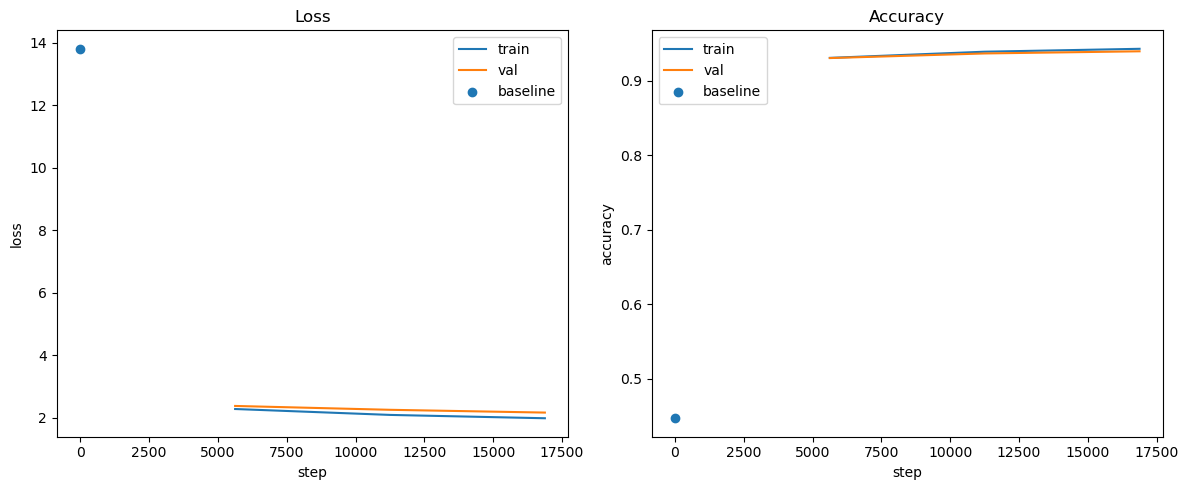

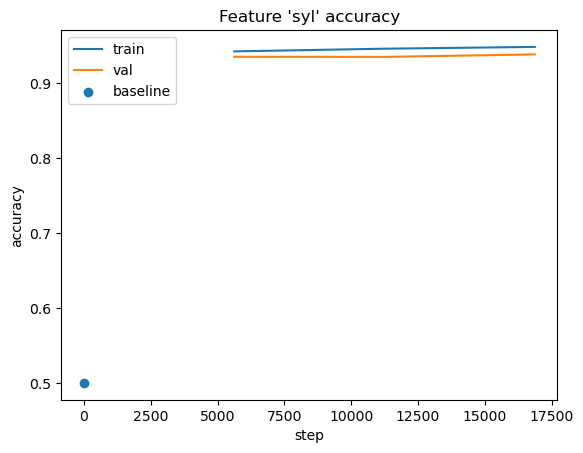

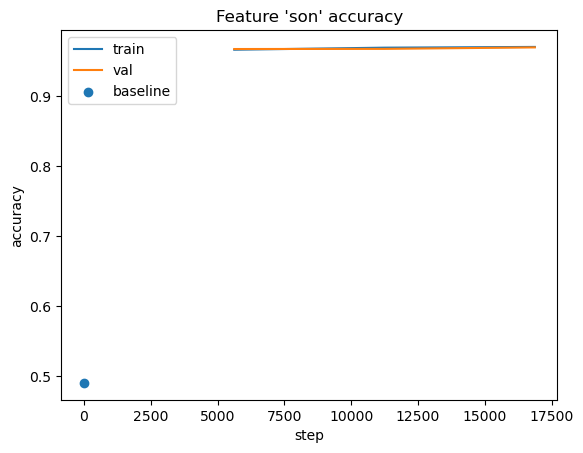

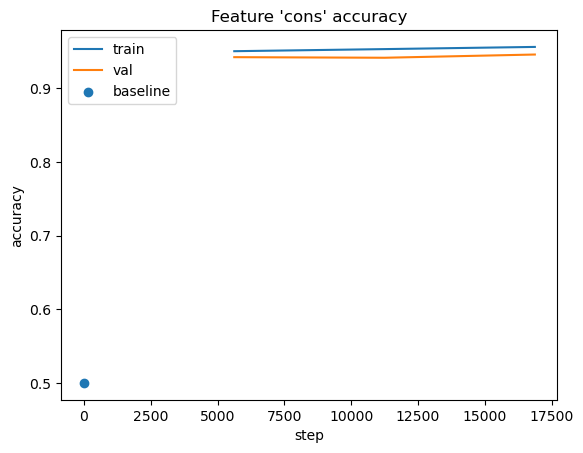

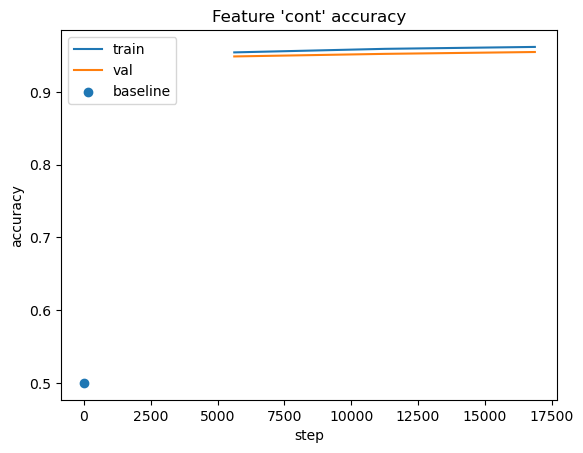

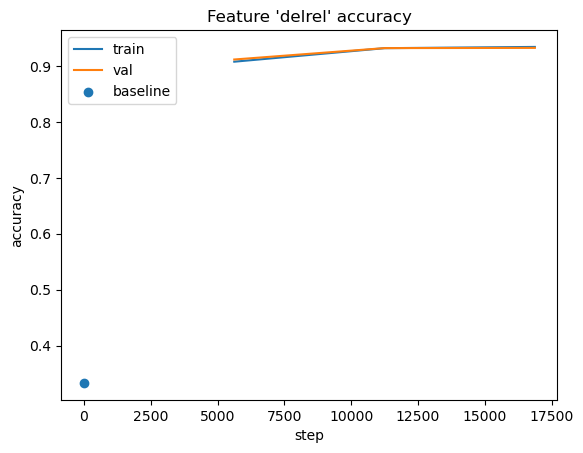

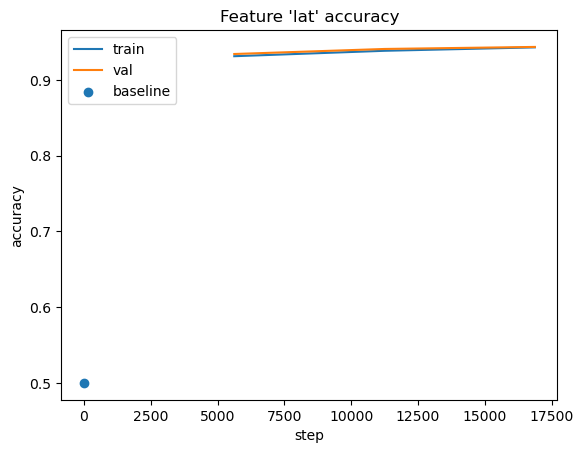

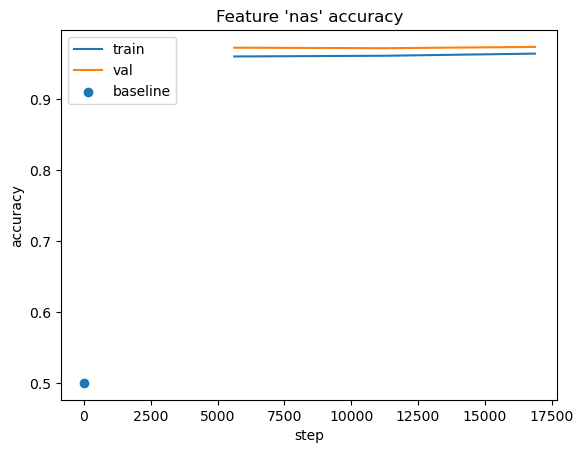

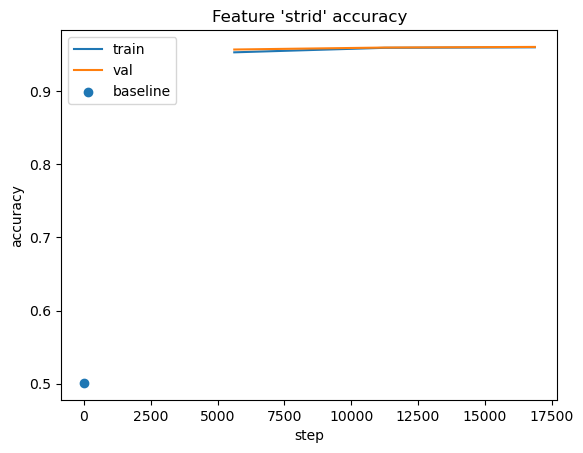

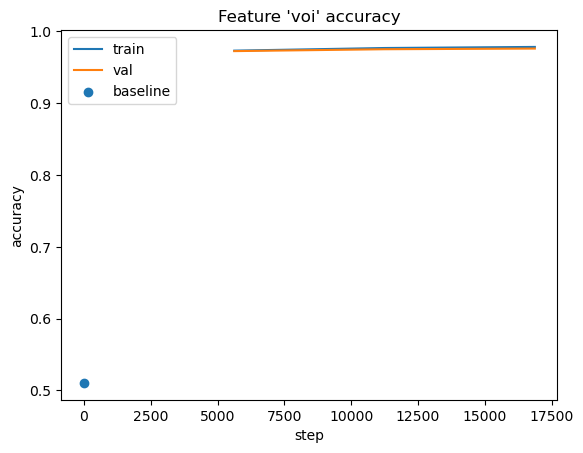

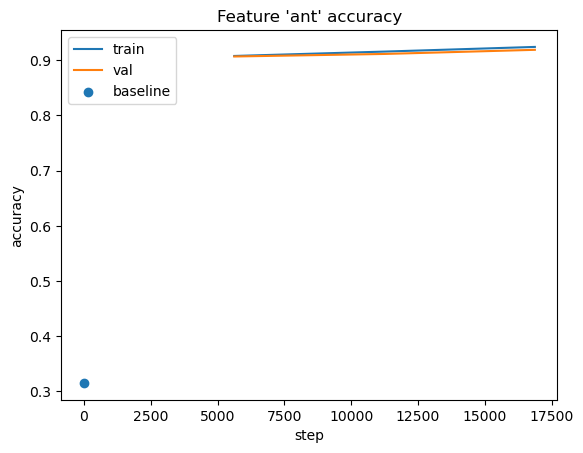

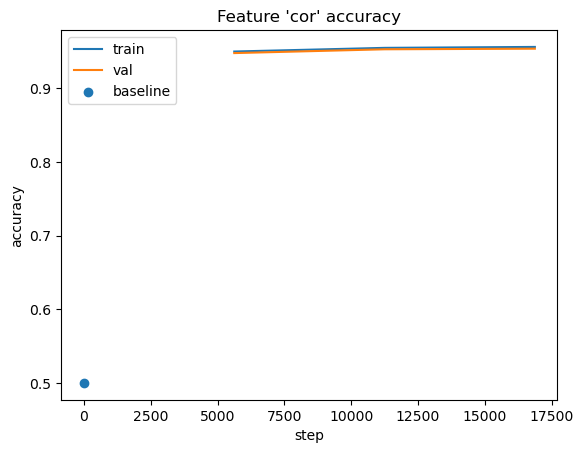

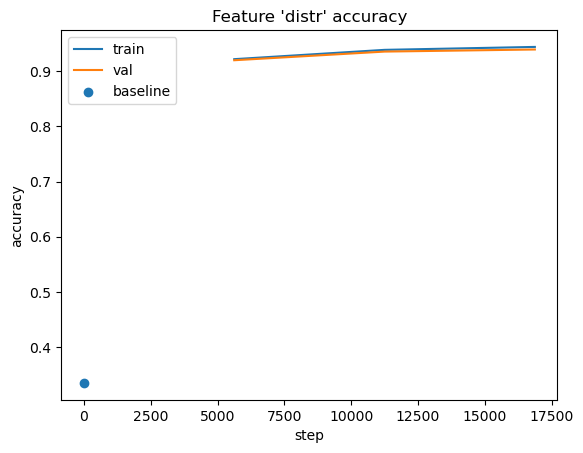

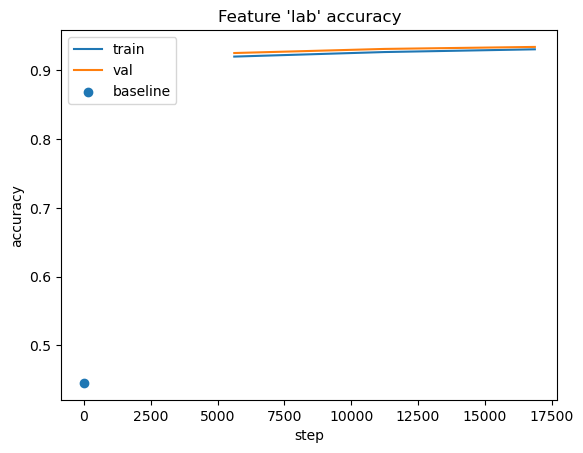

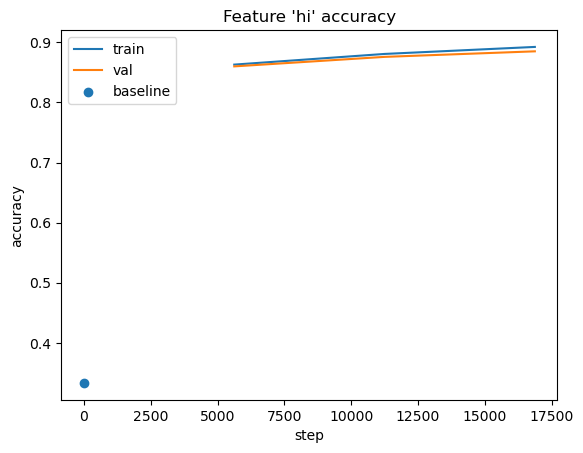

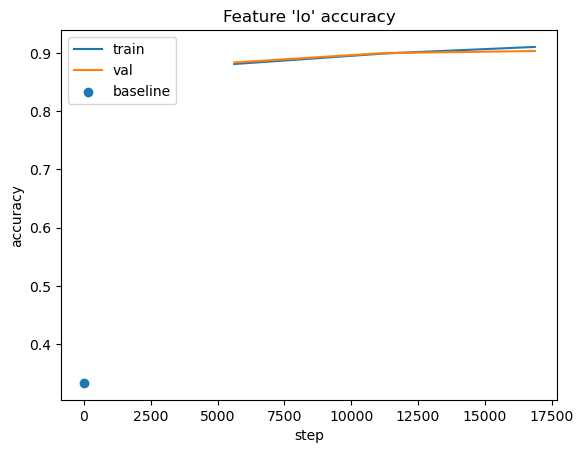

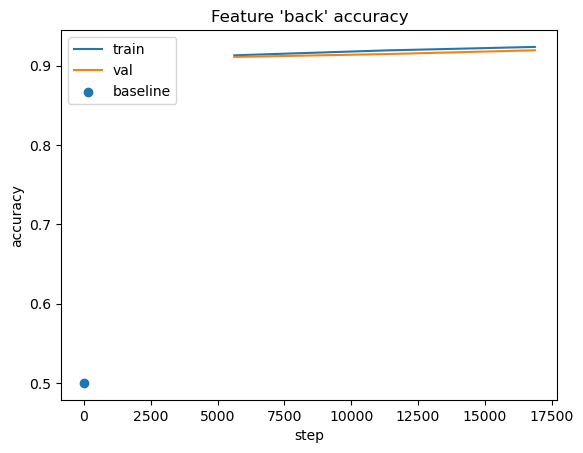

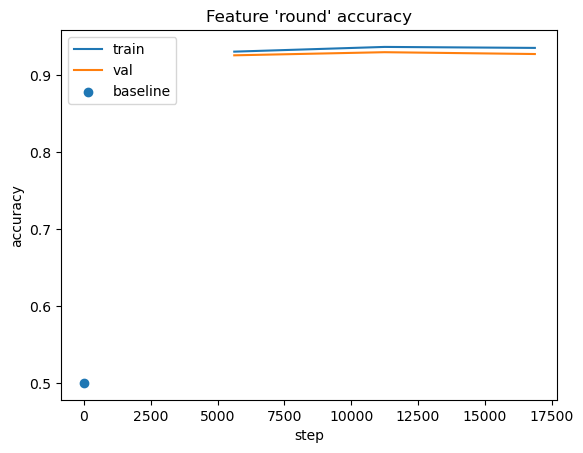

In [30]:
plot_training(history, baseline_loss, baseline_acc)
plot_feature_accuracy(history, baseline_feature_acc, FEATURE_NAMES, active_heads)

In [31]:
confusion_matrices = compute_confusion_matrices(model, train_loader, device, active_heads)

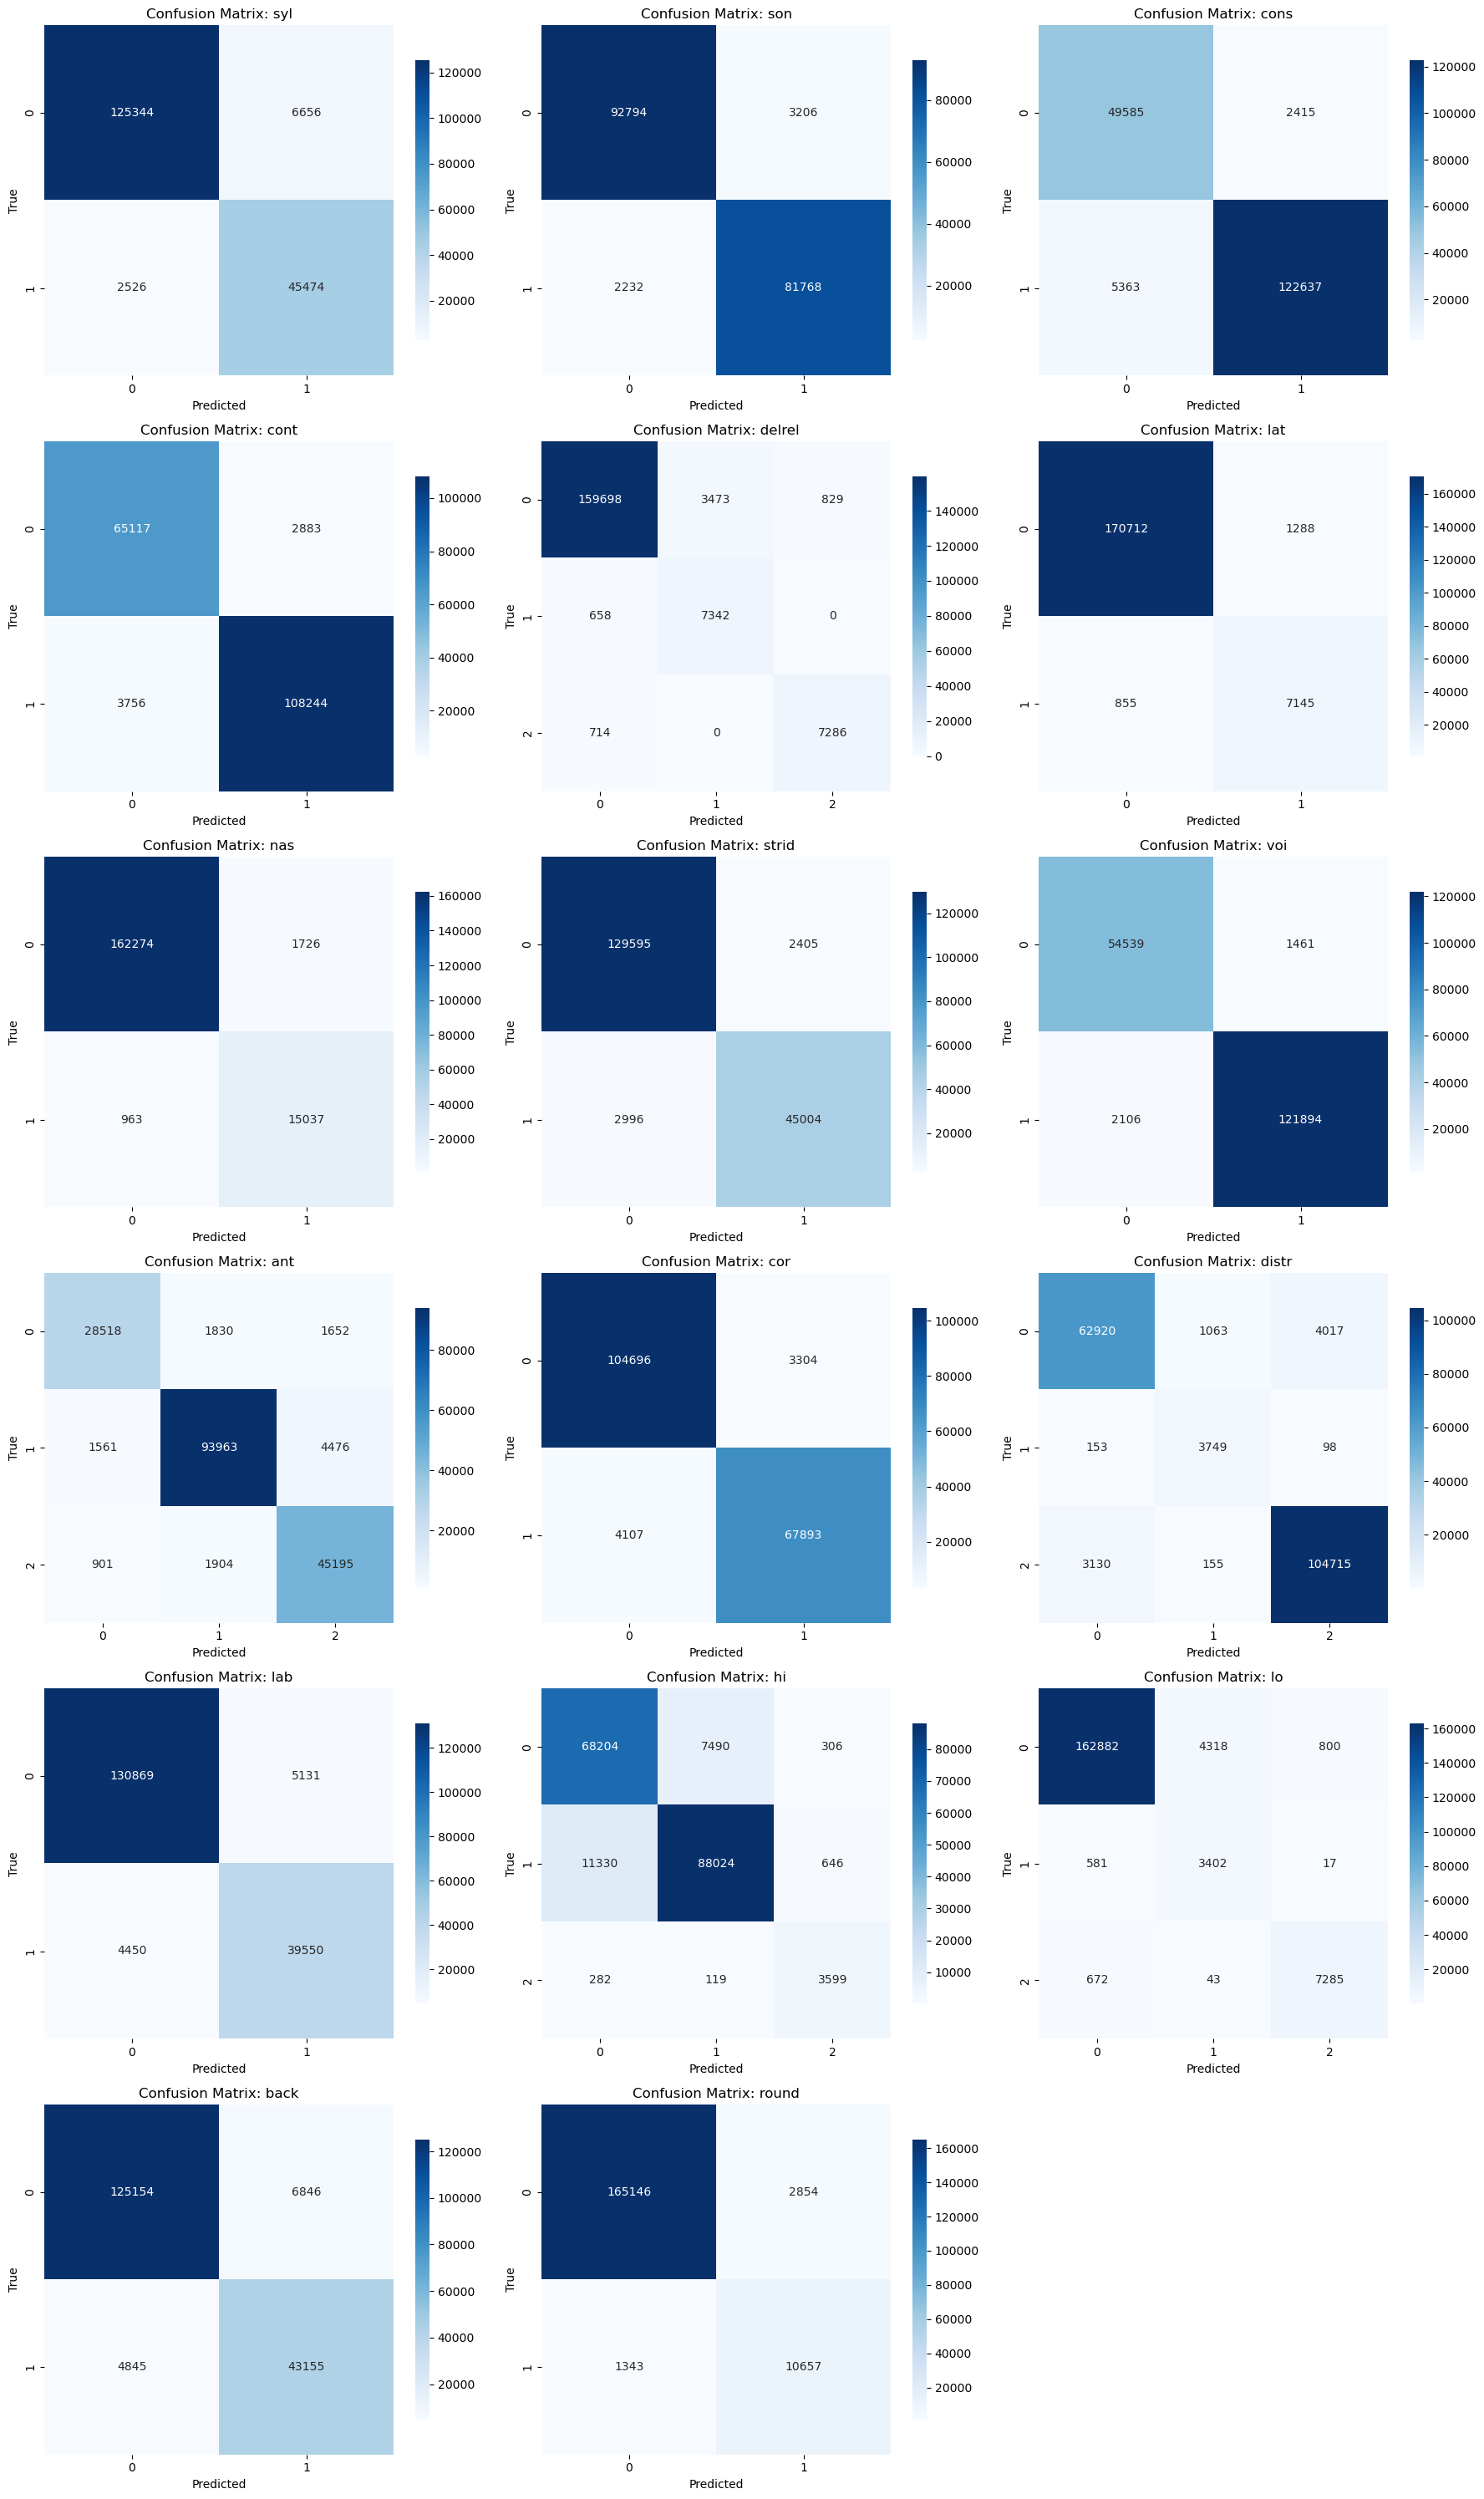

In [32]:
plot_confusion_matrices(confusion_matrices, FEATURE_NAMES)

In [33]:
сonfusion_matrices = compute_confusion_matrices(model, test_loader, device, active_heads)

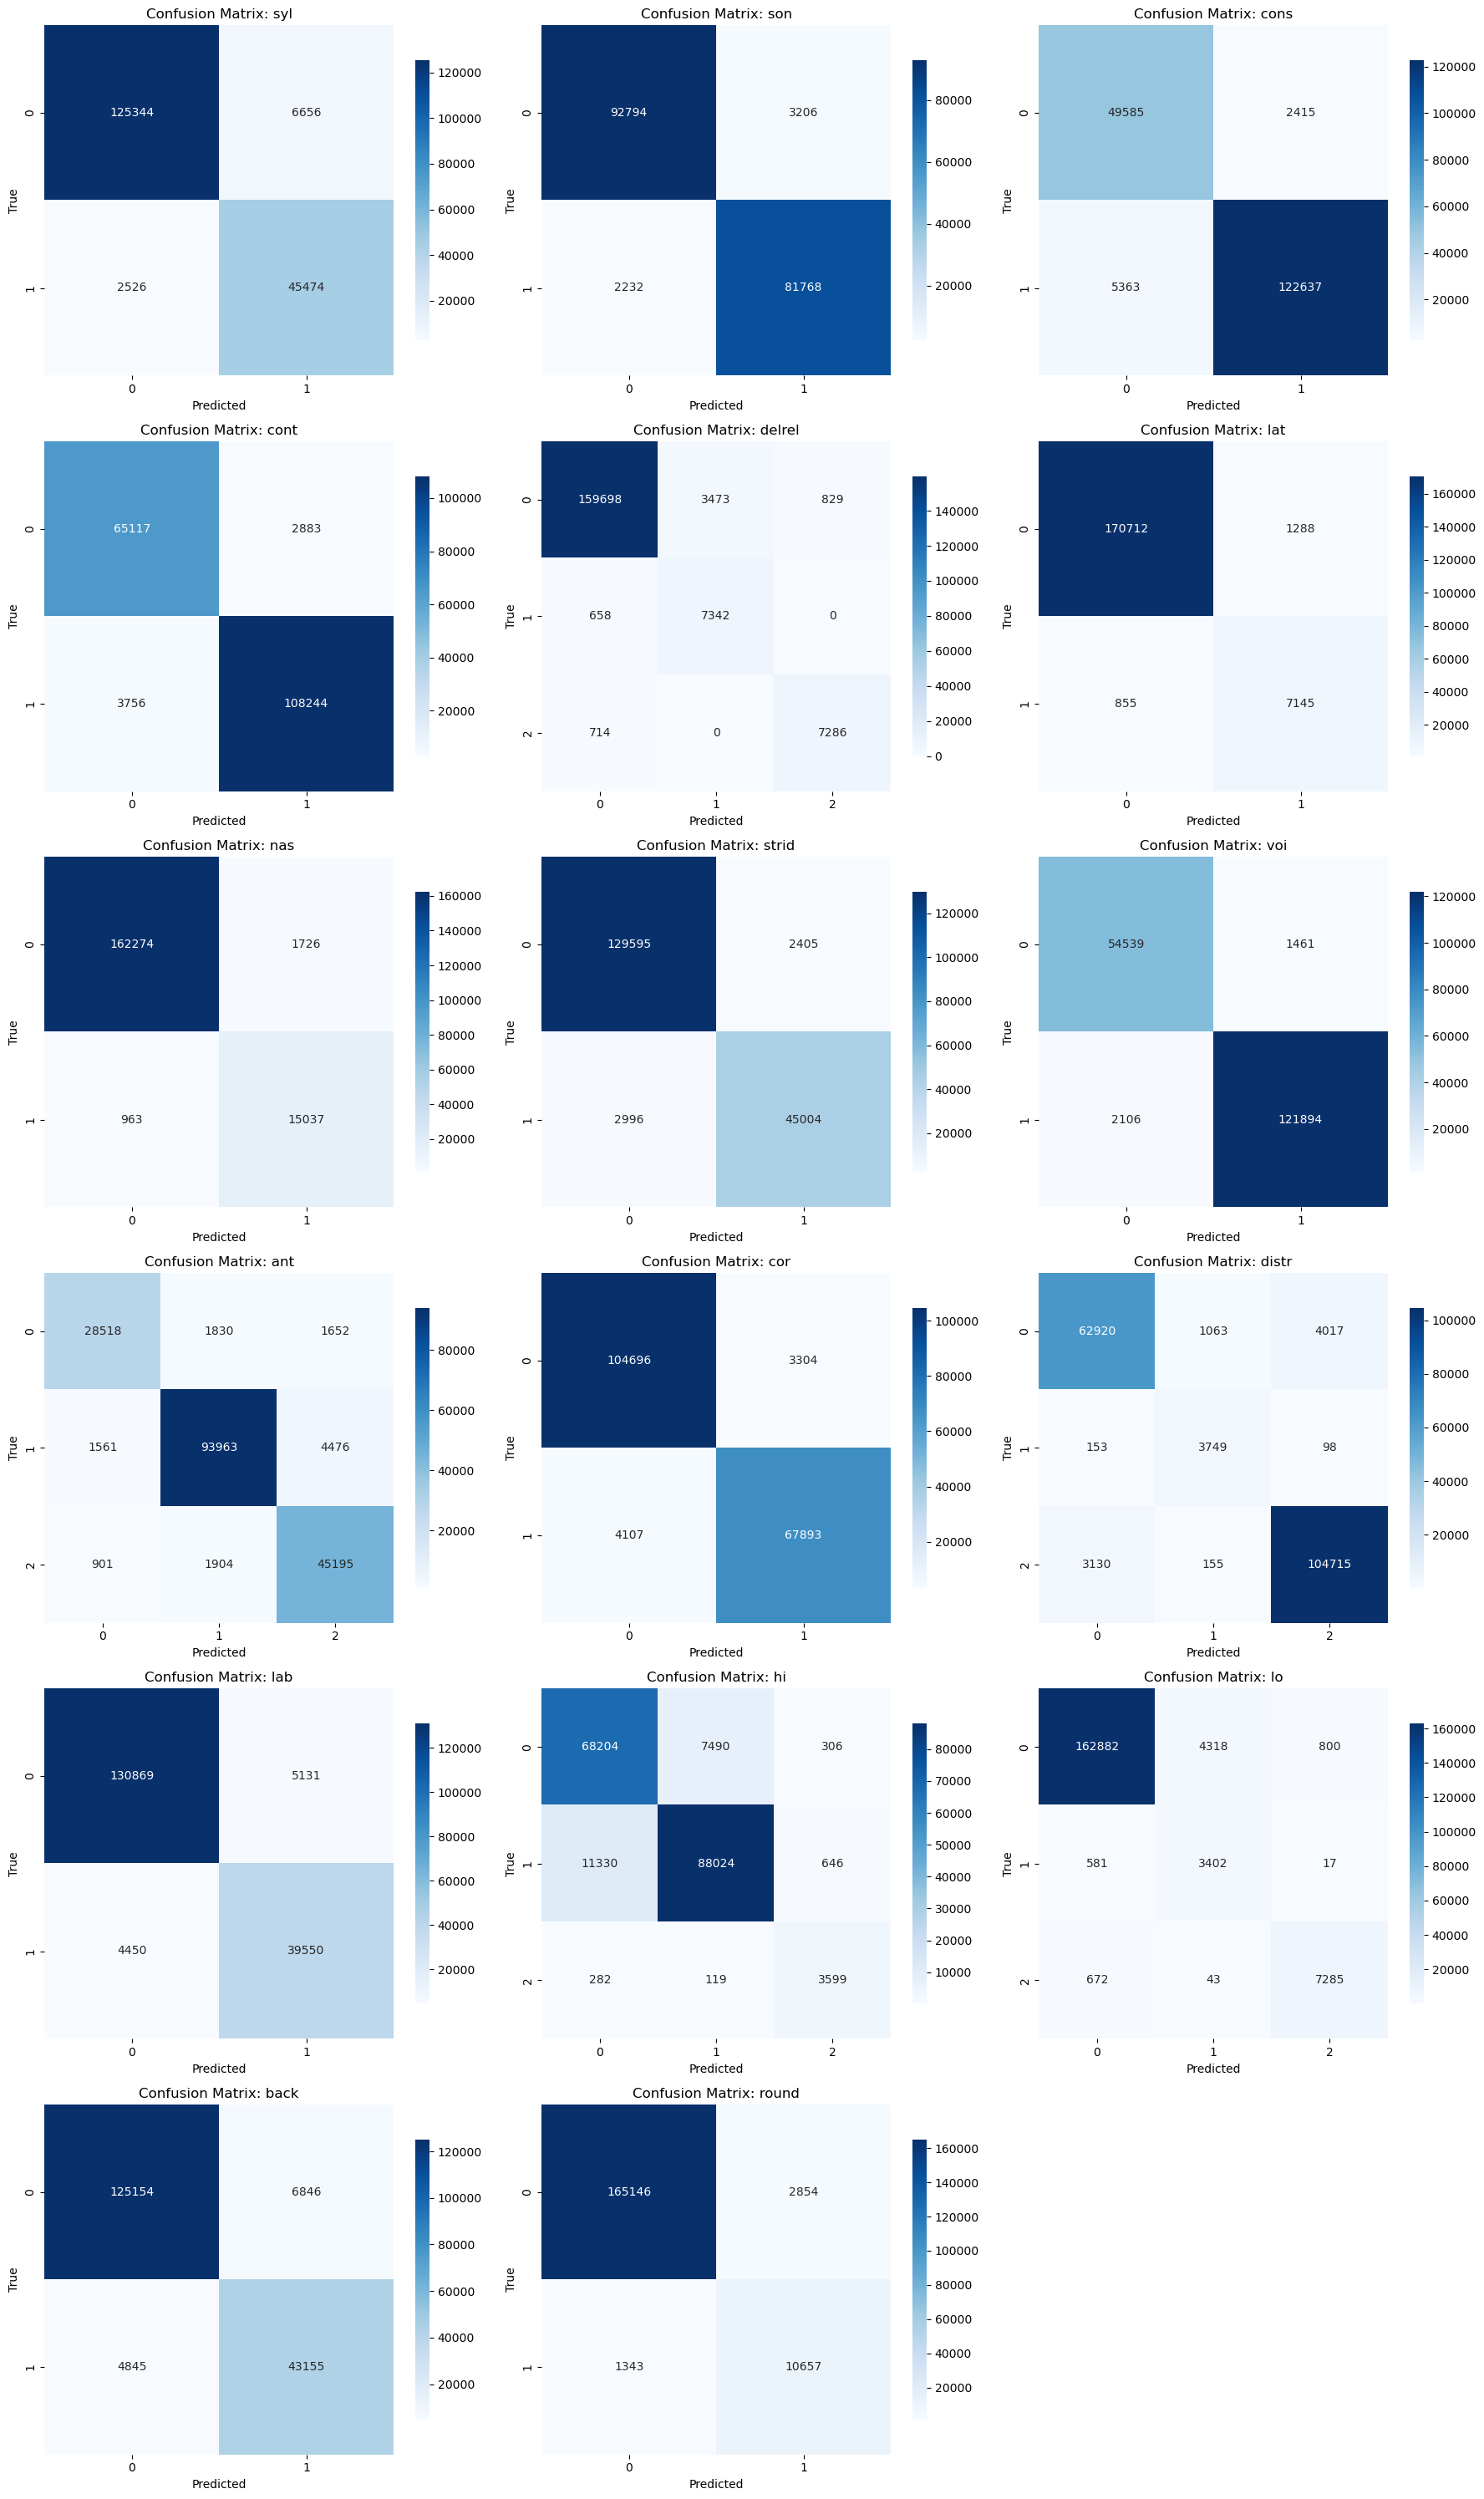

In [34]:
plot_confusion_matrices(confusion_matrices, FEATURE_NAMES)

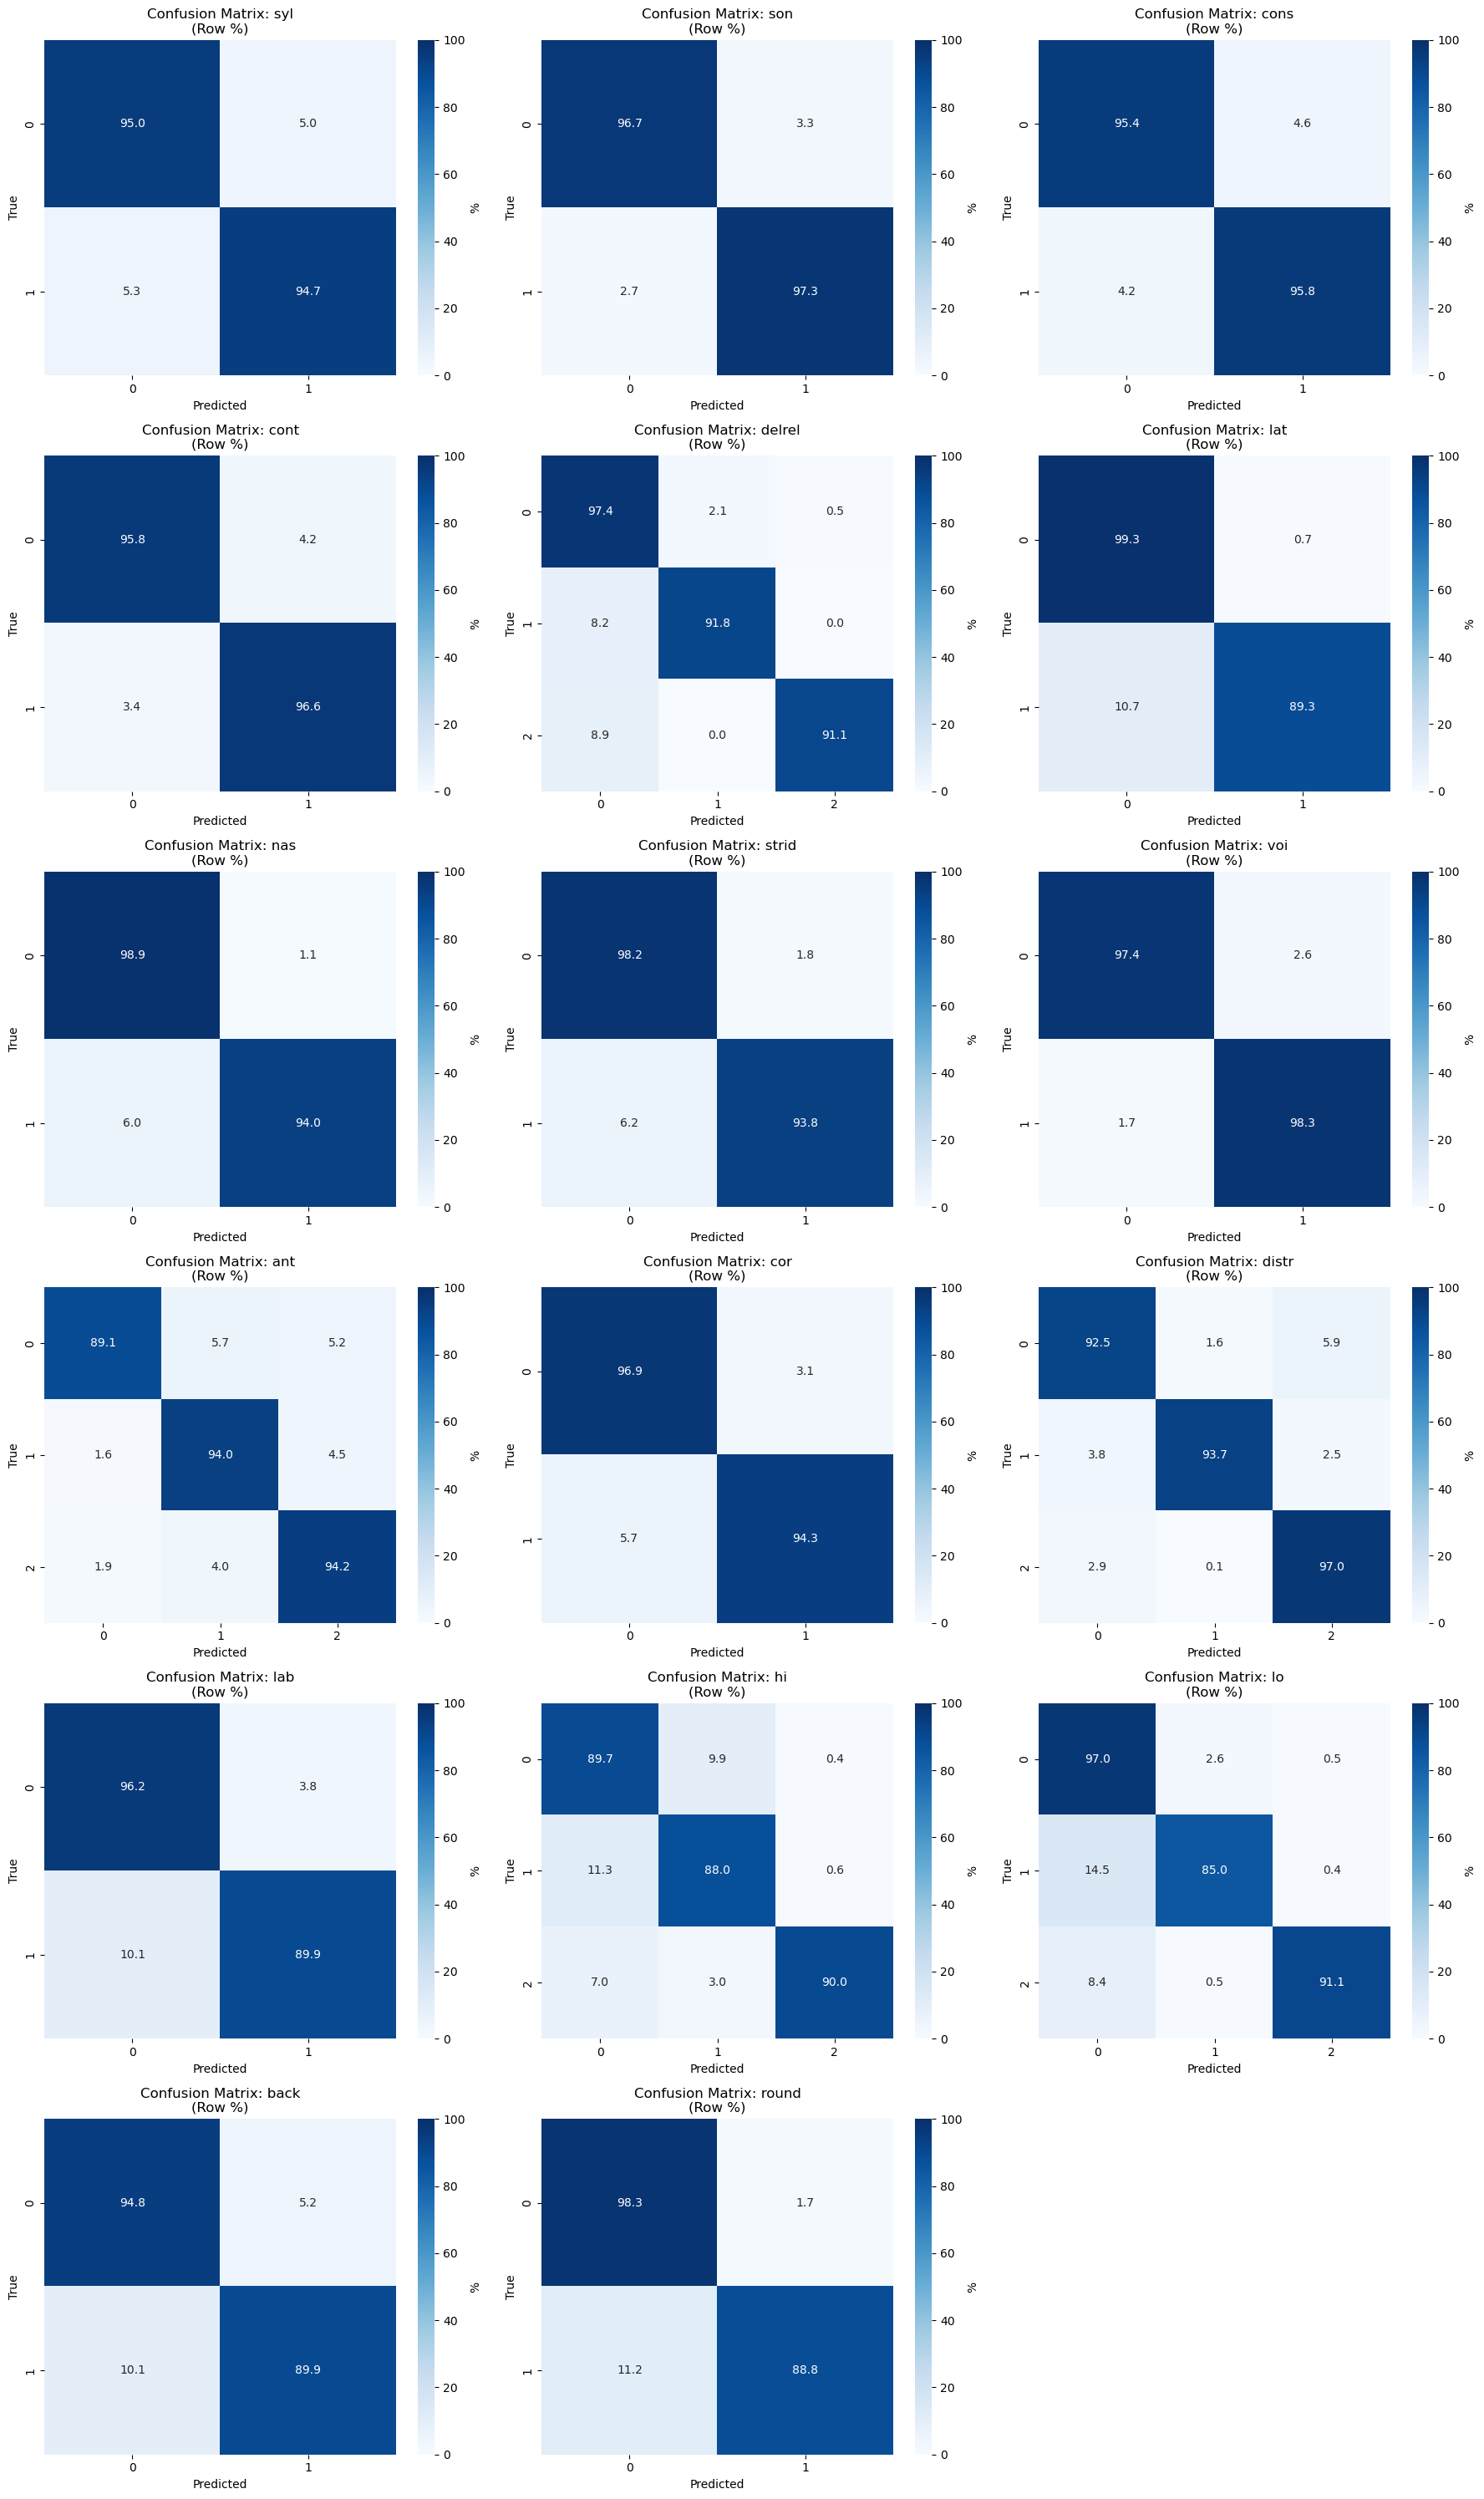

In [35]:
plot_confusion_matrices_norm(confusion_matrices, FEATURE_NAMES)

## Inference

In [36]:
checkpoint = torch.load(save_model_path, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
if checkpoint["scheduler_state_dict"] is not None:
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

In [37]:
model.eval()

PhonemeFeaturePredictor(
  (backbone): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
  )
  (heads): ModuleList(
    (0): Linear(in_features=128, out_features=2, bias=True)
    (1): Linear(in_features=128, out_features=2, bias=True)
    (2): Linear(in_features=128, out_features=2, bias=True)
    (3): Linear(in_features=128, out_features=2, bias=True)
    (4): Linear(in_features=128, out_features=3, bias=True)
    (5): Linear(in_features=128, out_features=2, bias=True)
    (6): Linear(in_features=128, out_features=2, bias=True)
    (7): Linear(in_features=128, out_features=2, bias=True)
    (8): Linear(in_features=128, out_features=2, bias=True)
    (9): Linear(in_features=128, out_features=1, bias=True)
    (10): Linear(in_features=128, out_features=1, bias=True)
    (11): Linear(in_features=128, out_features=3, bias=True)
    (12): Linear(in_features=128, out_features=2, bias=True)
    (13): Linear(in_fe

In [38]:
inspect_single_prediction(model, test_dataset, device, active_heads, FEATURE_NAMES, skip_symbols={"k", "a"})

Symbol: r
syl 0 0
son 1 1
cons 1 1
cont 1 1
delrel 2 2
lat 0 0
nas 0 0
strid 0 0
voi 1 1
ant 1 1
cor 1 1
distr 0 0
lab 0 0
hi 2 2
lo 2 2
back 0 0
round 0 0


In [39]:
stats, true_classes = collect_symbol_prediction_stats(model, test_dataset, device, active_heads)

In [40]:
symbol_features = [
    {
        "symbol": symbol,
        "head": head_id,
        "counts": dict(class_counts),
        "true_class": true_classes[(symbol, head_id)],
    }
    for symbol, heads_dict in stats.items()
    for head_id, class_counts in heads_dict.items()
]


In [41]:
symbol_features


[{'symbol': 'k', 'head': 0, 'counts': {0: 3960, 1: 40}, 'true_class': 0},
 {'symbol': 'k', 'head': 1, 'counts': {0: 3945, 1: 55}, 'true_class': 0},
 {'symbol': 'k', 'head': 2, 'counts': {1: 3958, 0: 42}, 'true_class': 1},
 {'symbol': 'k', 'head': 3, 'counts': {0: 3897, 1: 103}, 'true_class': 0},
 {'symbol': 'k',
  'head': 4,
  'counts': {0: 3976, 1: 14, 2: 10},
  'true_class': 0},
 {'symbol': 'k', 'head': 5, 'counts': {0: 3990, 1: 10}, 'true_class': 0},
 {'symbol': 'k', 'head': 6, 'counts': {0: 3989, 1: 11}, 'true_class': 0},
 {'symbol': 'k', 'head': 7, 'counts': {0: 3977, 1: 23}, 'true_class': 0},
 {'symbol': 'k', 'head': 8, 'counts': {0: 3930, 1: 70}, 'true_class': 0},
 {'symbol': 'k',
  'head': 11,
  'counts': {1: 189, 0: 3772, 2: 39},
  'true_class': 0},
 {'symbol': 'k', 'head': 12, 'counts': {0: 3910, 1: 90}, 'true_class': 0},
 {'symbol': 'k',
  'head': 13,
  'counts': {2: 3915, 1: 12, 0: 73},
  'true_class': 2},
 {'symbol': 'k', 'head': 14, 'counts': {1: 223, 0: 3777}, 'true_clas

In [42]:
true_classes


{('k', 0): 0,
 ('k', 1): 0,
 ('k', 2): 1,
 ('k', 3): 0,
 ('k', 4): 0,
 ('k', 5): 0,
 ('k', 6): 0,
 ('k', 7): 0,
 ('k', 8): 0,
 ('k', 11): 0,
 ('k', 12): 0,
 ('k', 13): 2,
 ('k', 14): 0,
 ('k', 15): 1,
 ('k', 16): 0,
 ('k', 17): 1,
 ('k', 18): 0,
 ('a', 0): 1,
 ('a', 1): 1,
 ('a', 2): 0,
 ('a', 3): 1,
 ('a', 4): 0,
 ('a', 5): 0,
 ('a', 6): 0,
 ('a', 7): 0,
 ('a', 8): 1,
 ('a', 11): 2,
 ('a', 12): 0,
 ('a', 13): 2,
 ('a', 14): 0,
 ('a', 15): 0,
 ('a', 16): 1,
 ('a', 17): 1,
 ('a', 18): 0,
 ('r', 0): 0,
 ('r', 1): 1,
 ('r', 2): 1,
 ('r', 3): 1,
 ('r', 4): 2,
 ('r', 5): 0,
 ('r', 6): 0,
 ('r', 7): 0,
 ('r', 8): 1,
 ('r', 11): 1,
 ('r', 12): 1,
 ('r', 13): 0,
 ('r', 14): 0,
 ('r', 15): 2,
 ('r', 16): 2,
 ('r', 17): 0,
 ('r', 18): 0,
 ('z', 0): 0,
 ('z', 1): 0,
 ('z', 2): 1,
 ('z', 3): 1,
 ('z', 4): 0,
 ('z', 5): 0,
 ('z', 6): 0,
 ('z', 7): 1,
 ('z', 8): 1,
 ('z', 11): 1,
 ('z', 12): 1,
 ('z', 13): 0,
 ('z', 14): 0,
 ('z', 15): 0,
 ('z', 16): 0,
 ('z', 17): 0,
 ('z', 18): 0,
 ('ʌ', 0): 1,
 (

In [43]:
prediction_rows = build_prediction_rows(stats, true_classes)


In [44]:
prediction_rows[:5]


[{'symbol': 'k', 'head': 0, 'class': 0, 'count': 3960, 'true_class': 0},
 {'symbol': 'k', 'head': 0, 'class': 1, 'count': 40, 'true_class': 0},
 {'symbol': 'k', 'head': 1, 'class': 0, 'count': 3945, 'true_class': 0},
 {'symbol': 'k', 'head': 1, 'class': 1, 'count': 55, 'true_class': 0},
 {'symbol': 'k', 'head': 2, 'class': 1, 'count': 3958, 'true_class': 1}]

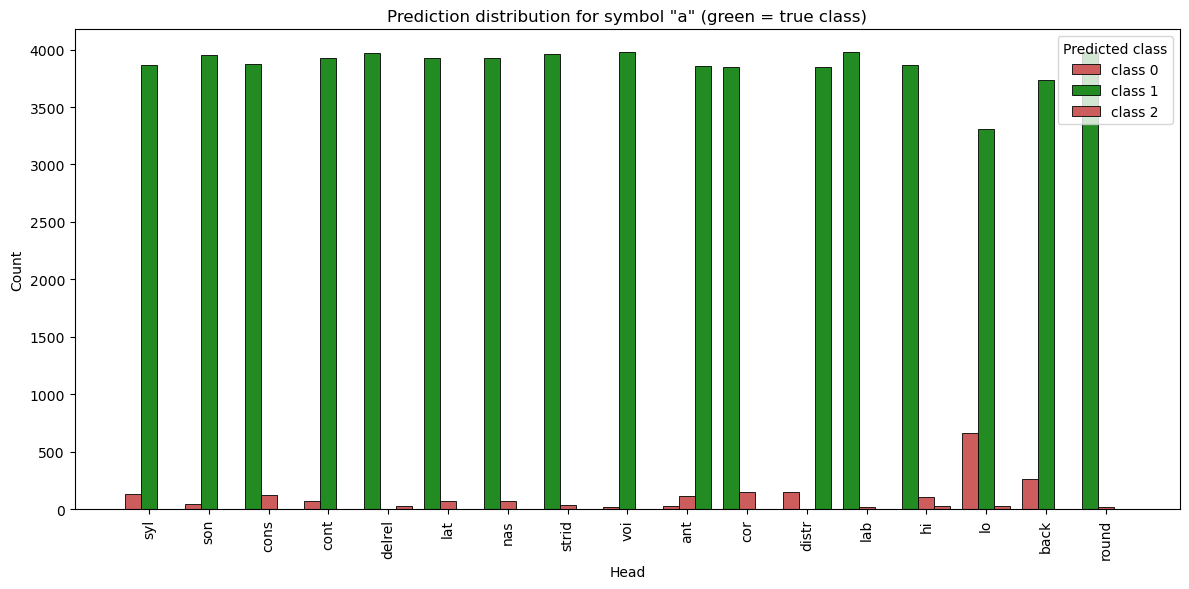

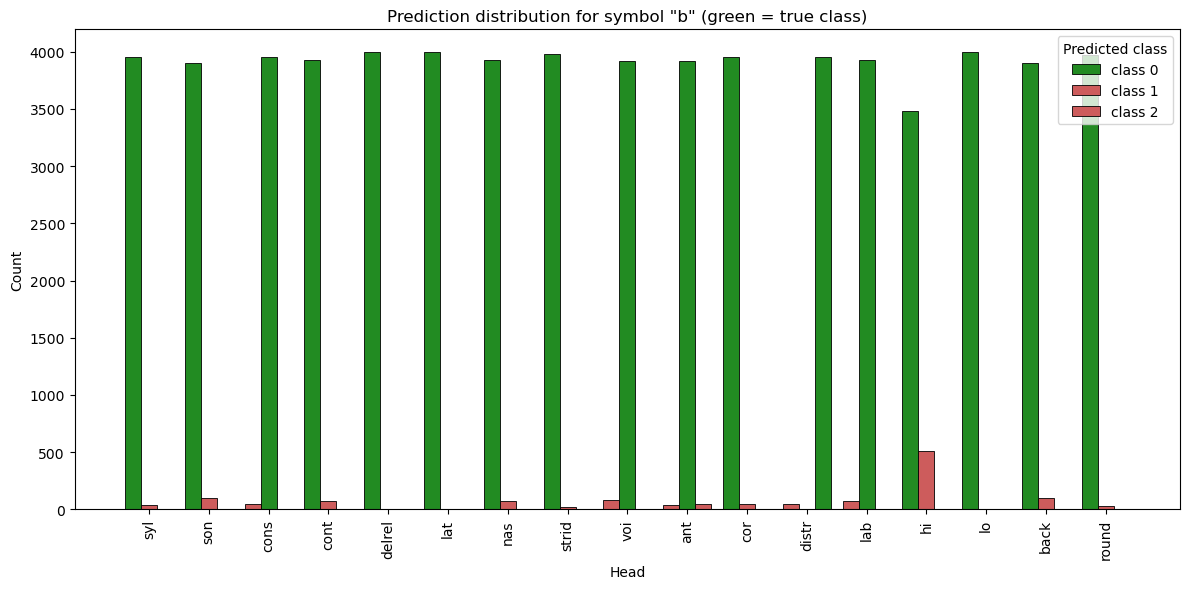

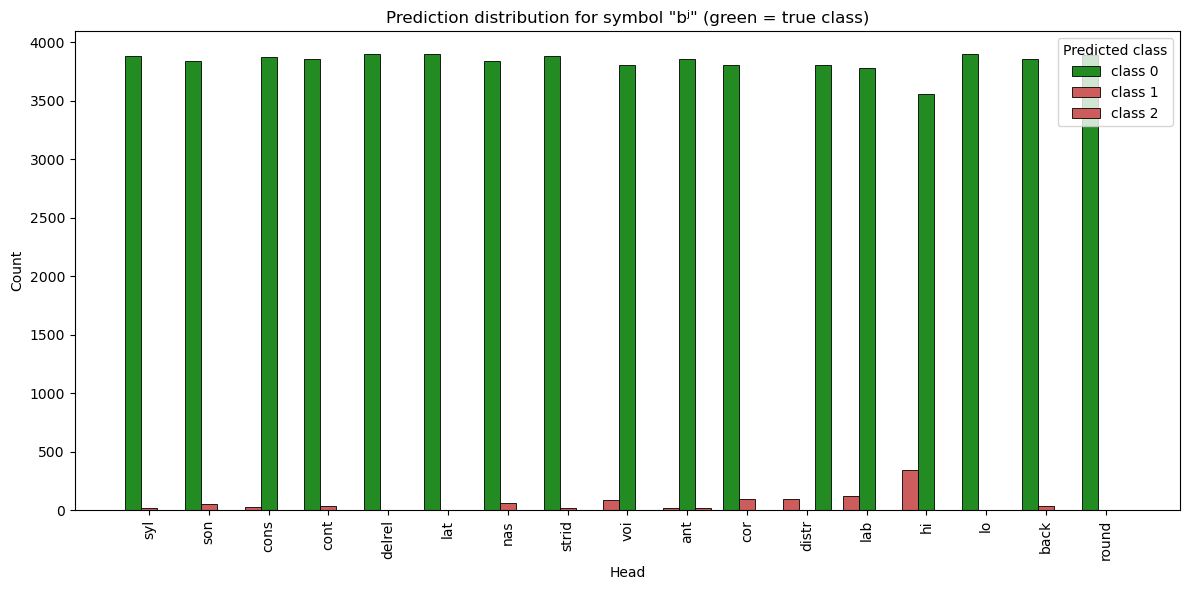

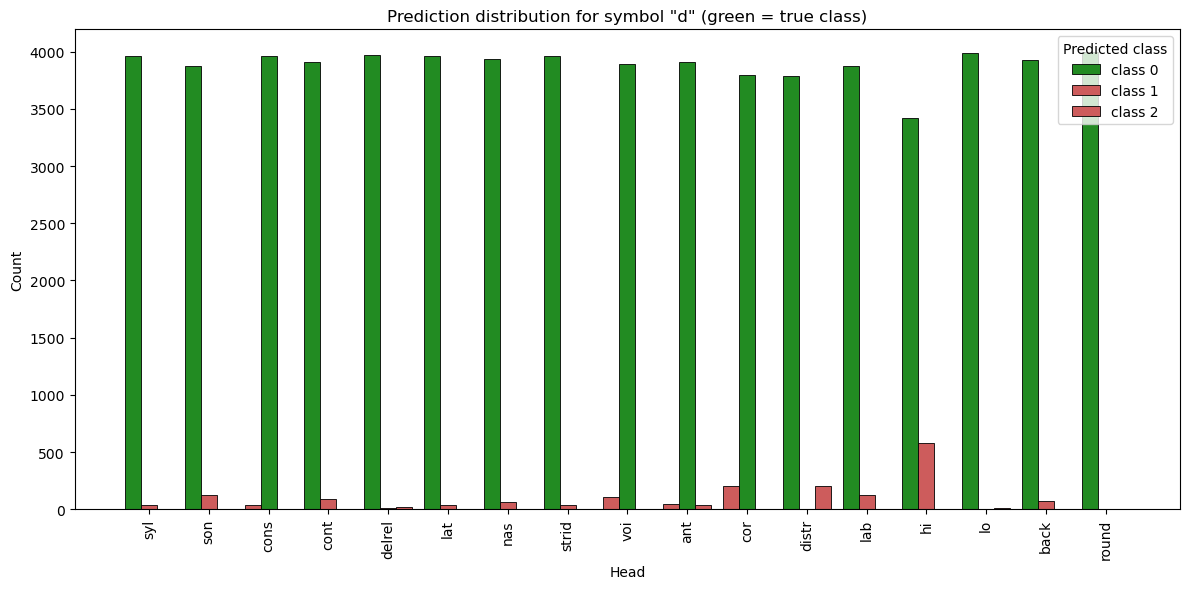

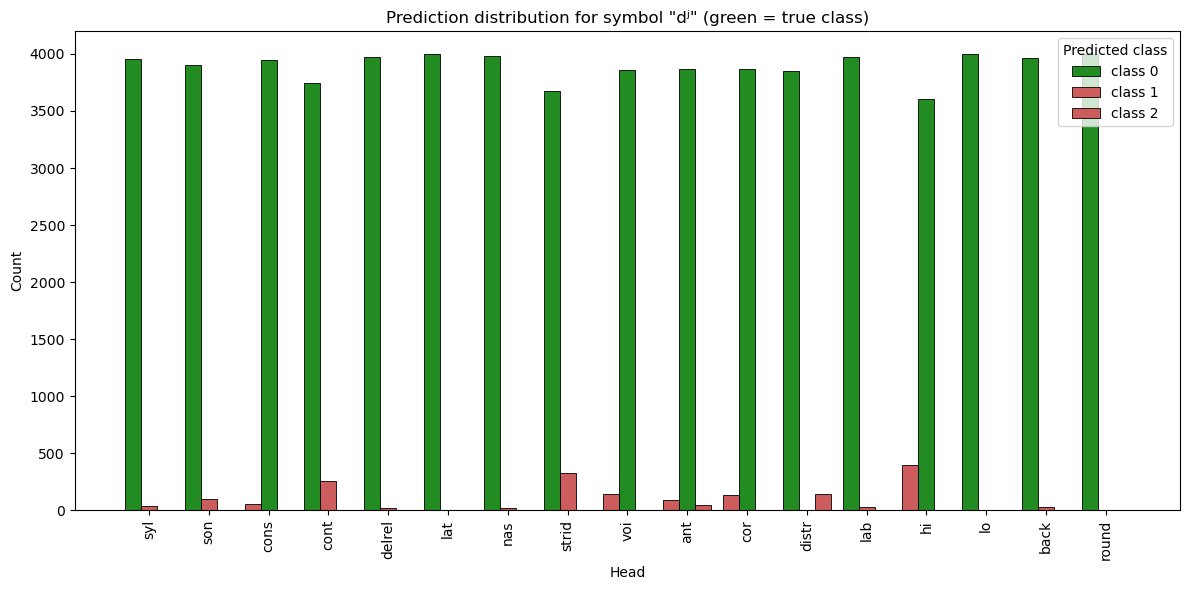

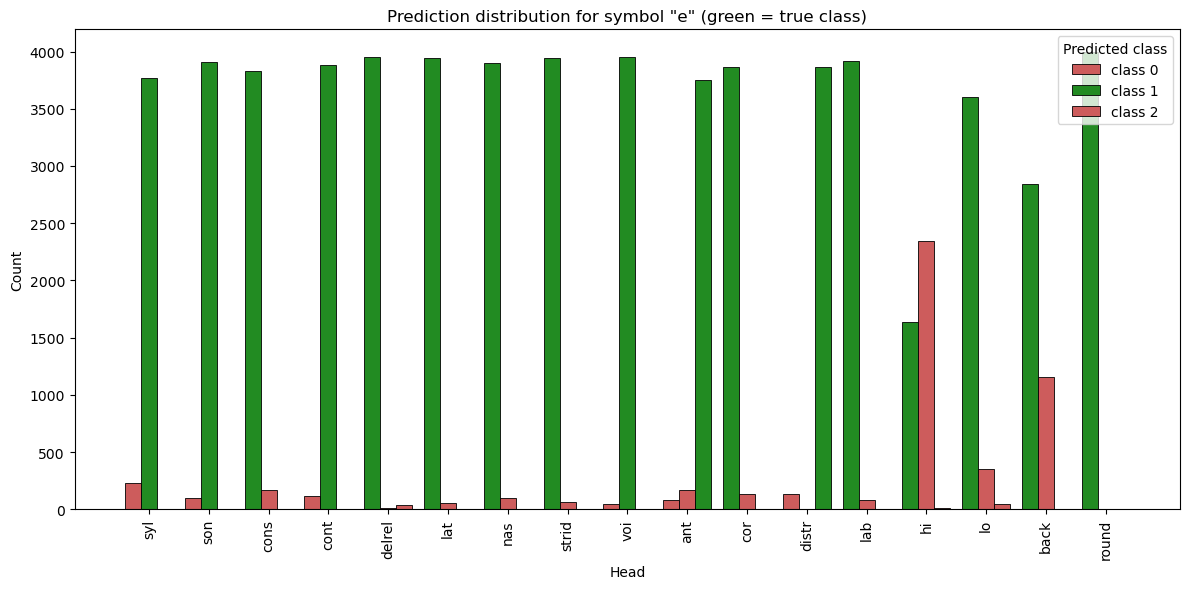

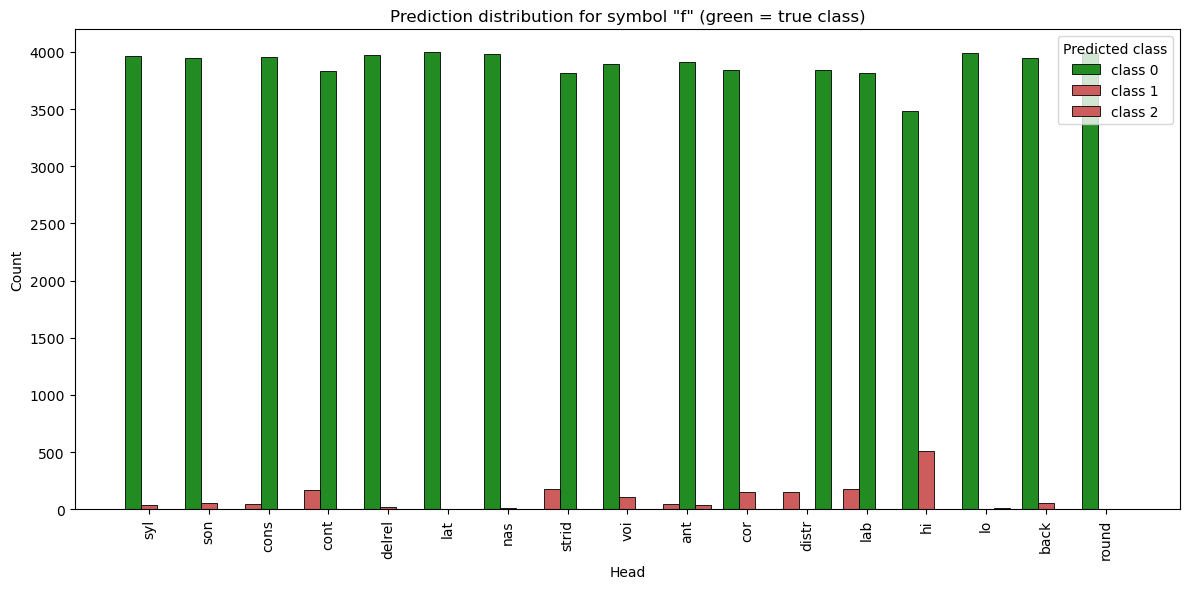

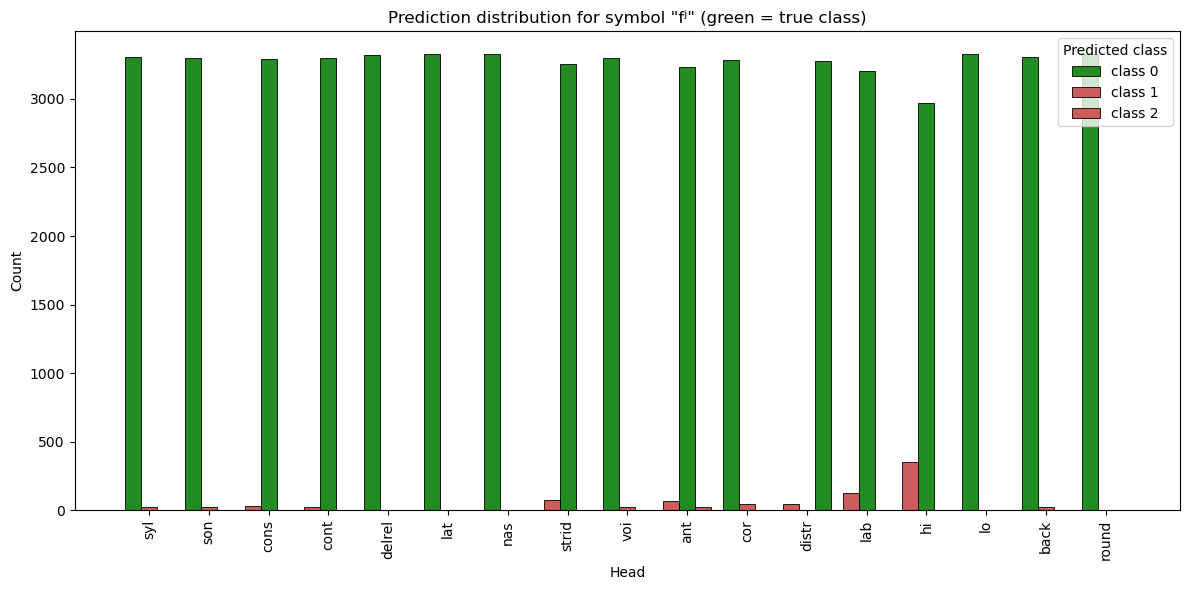

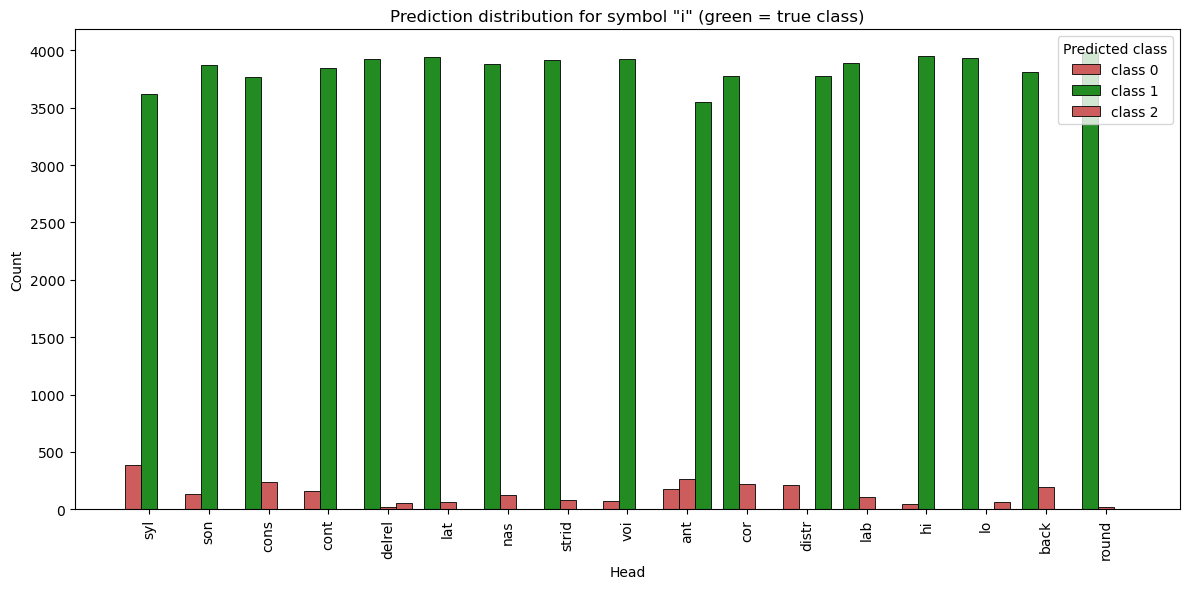

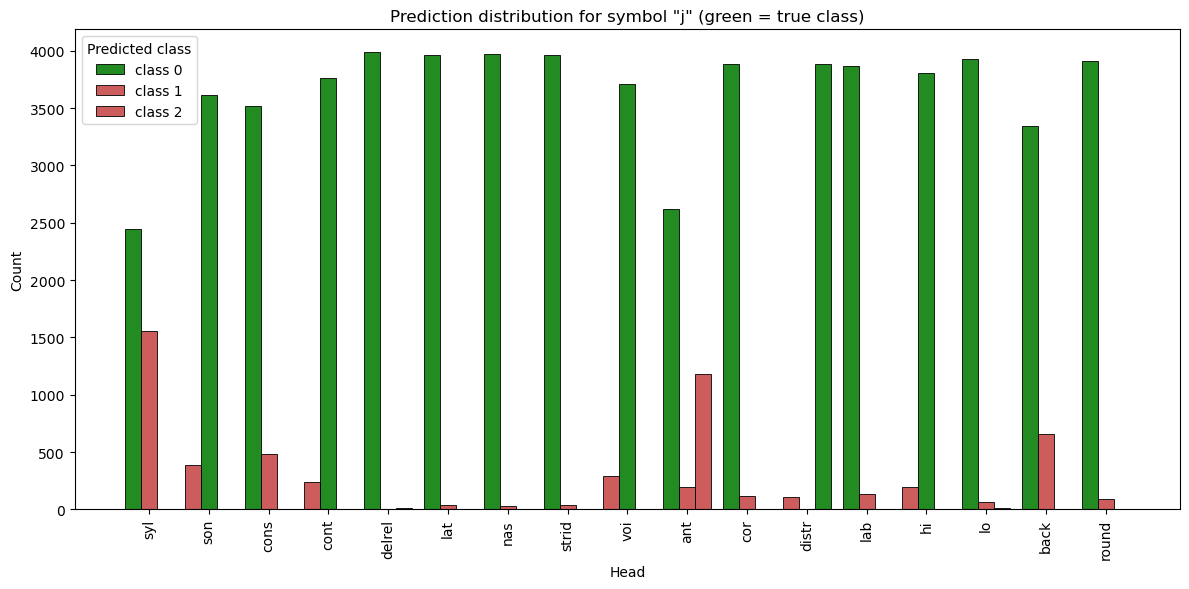

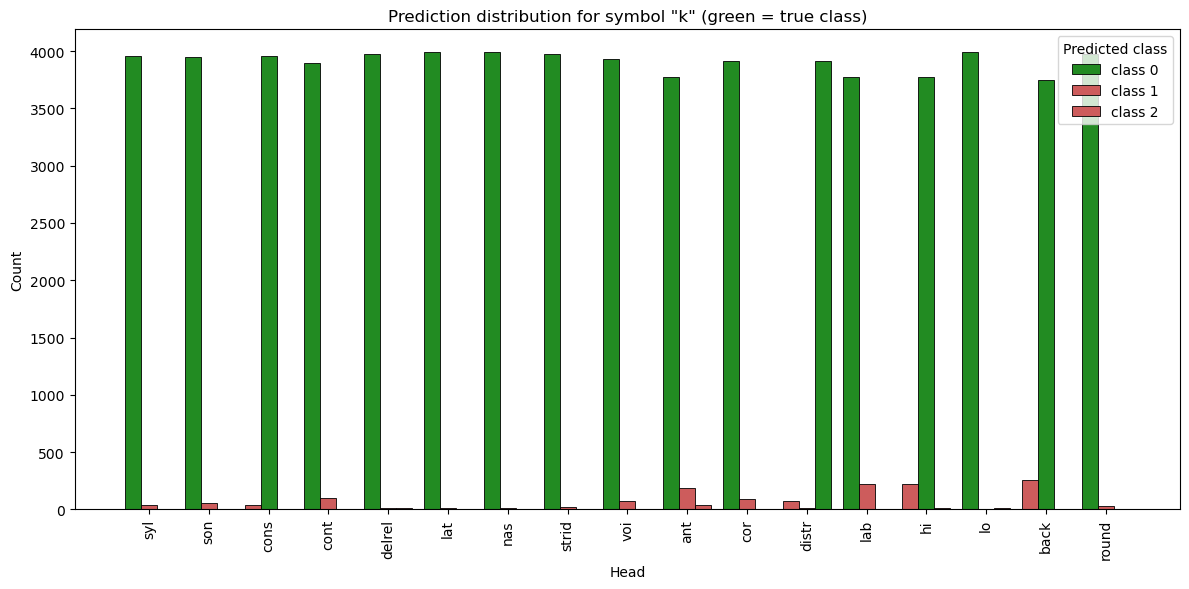

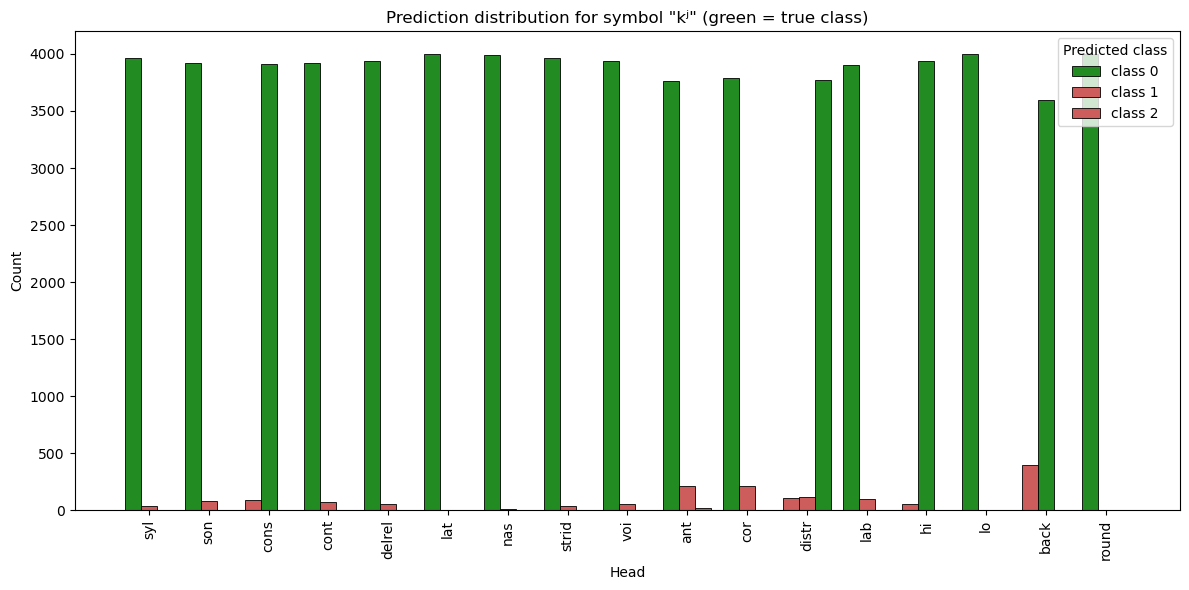

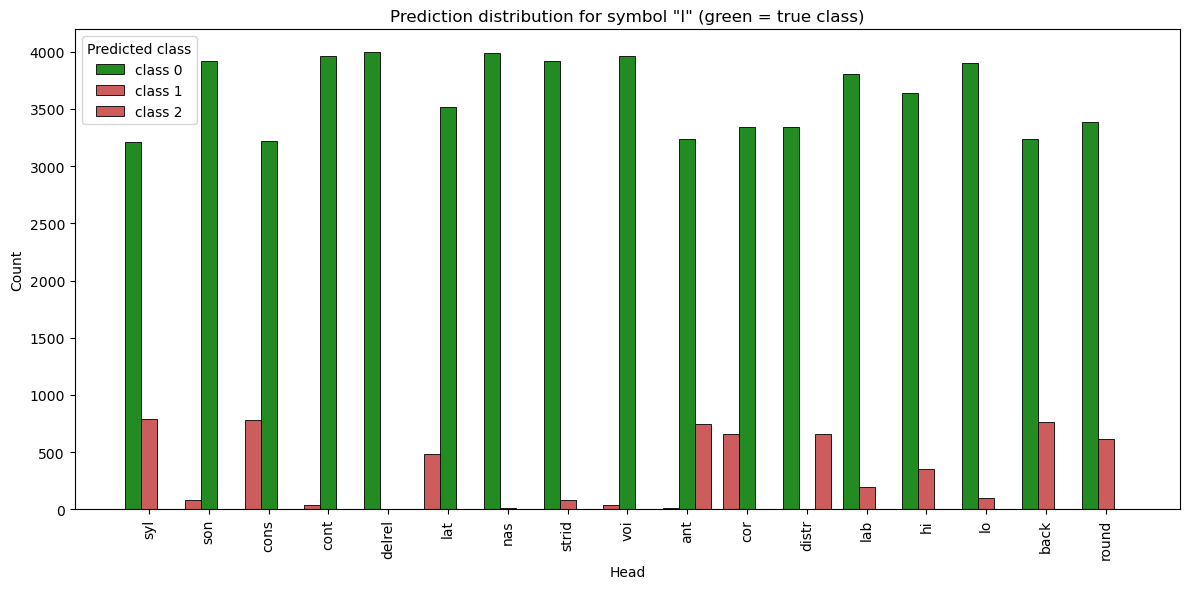

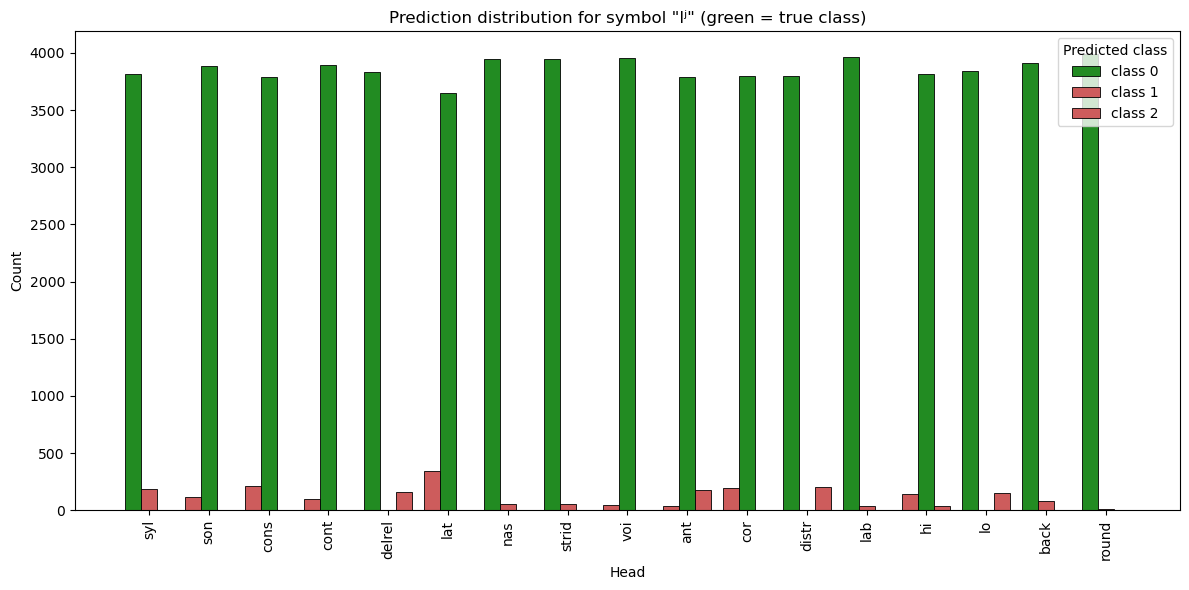

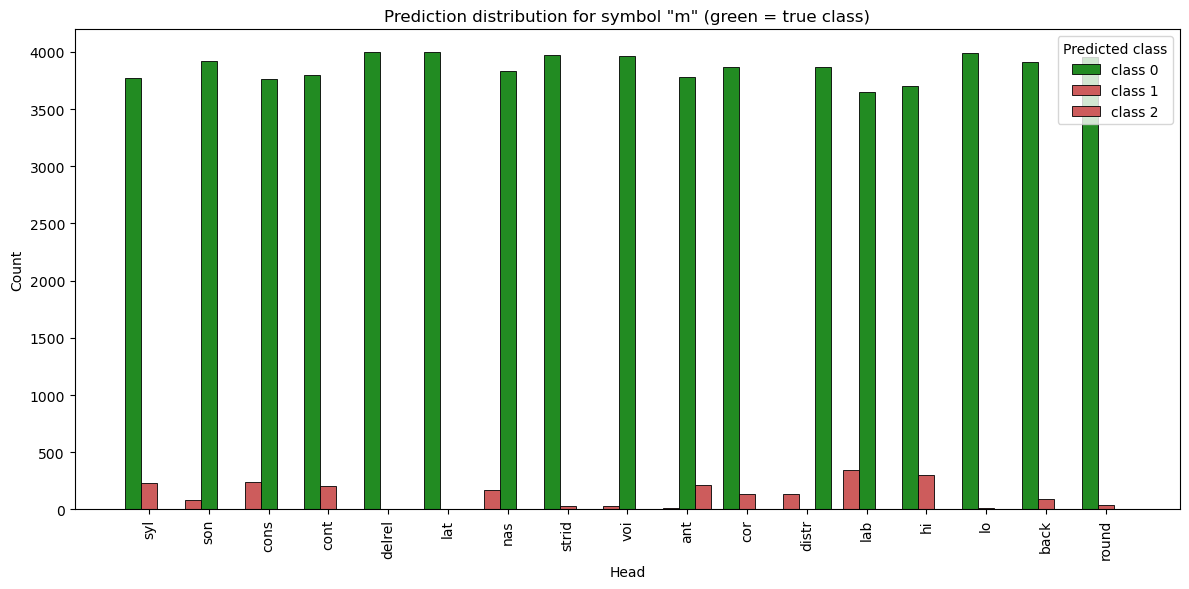

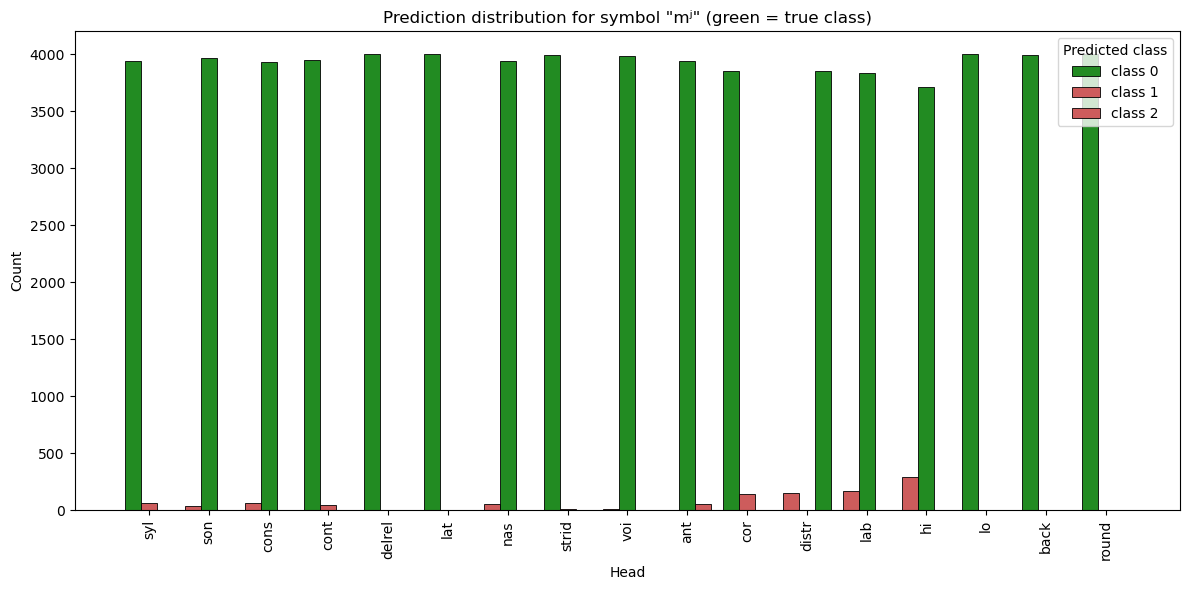

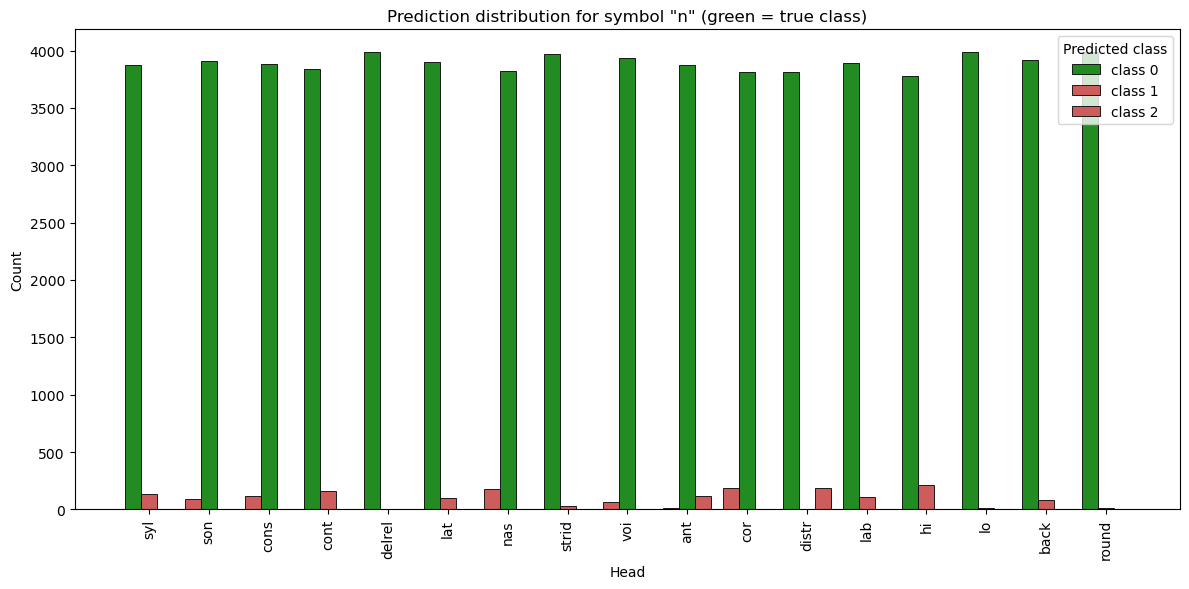

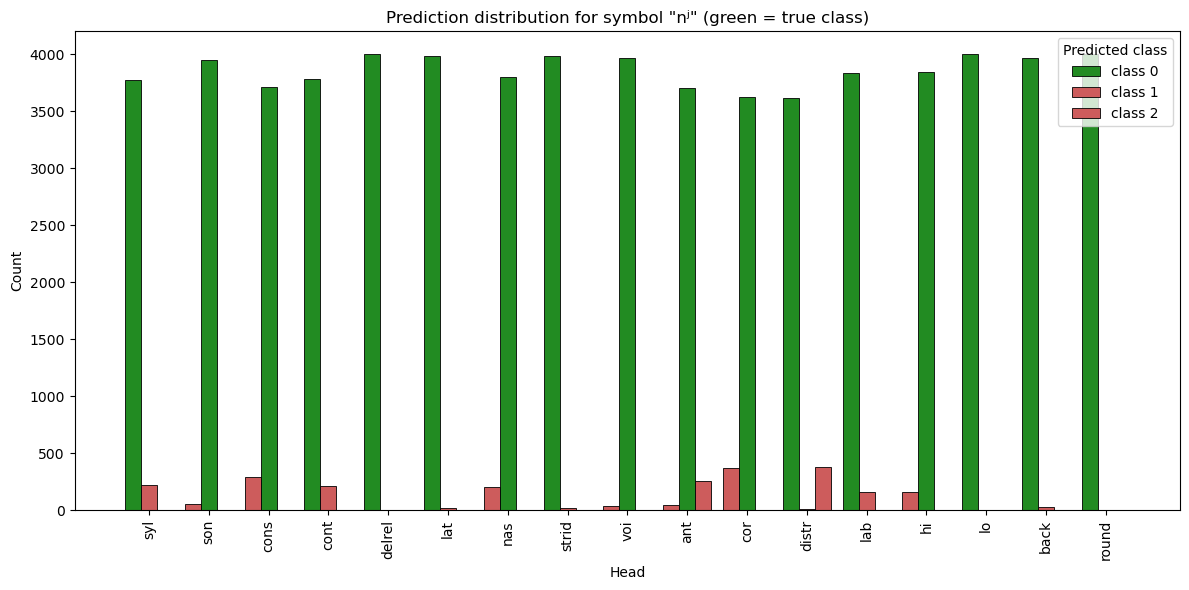

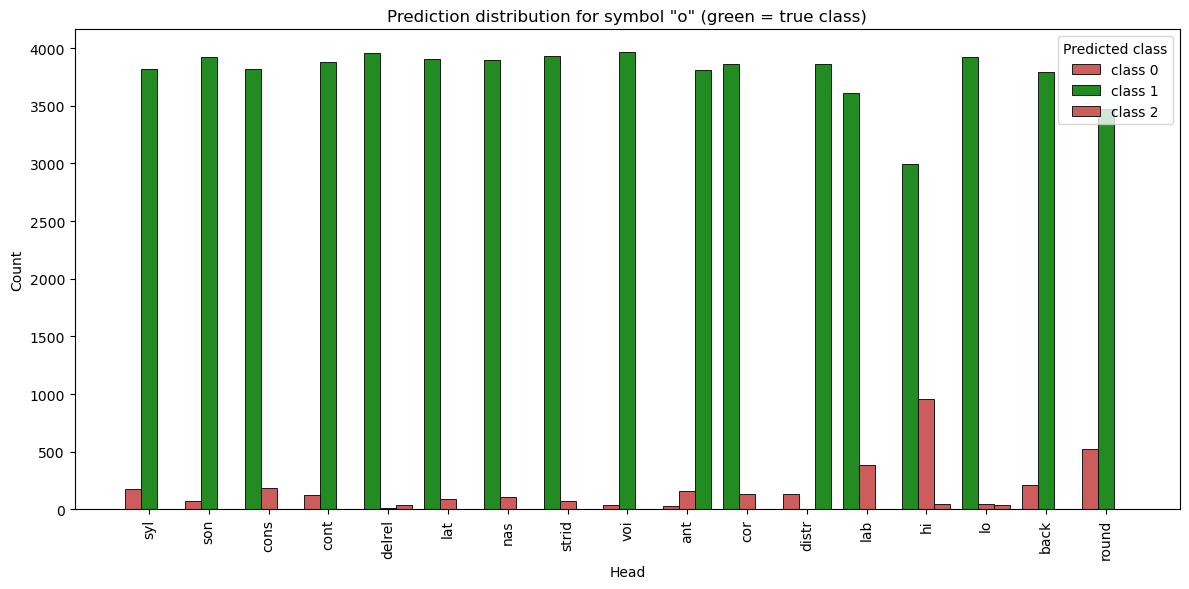

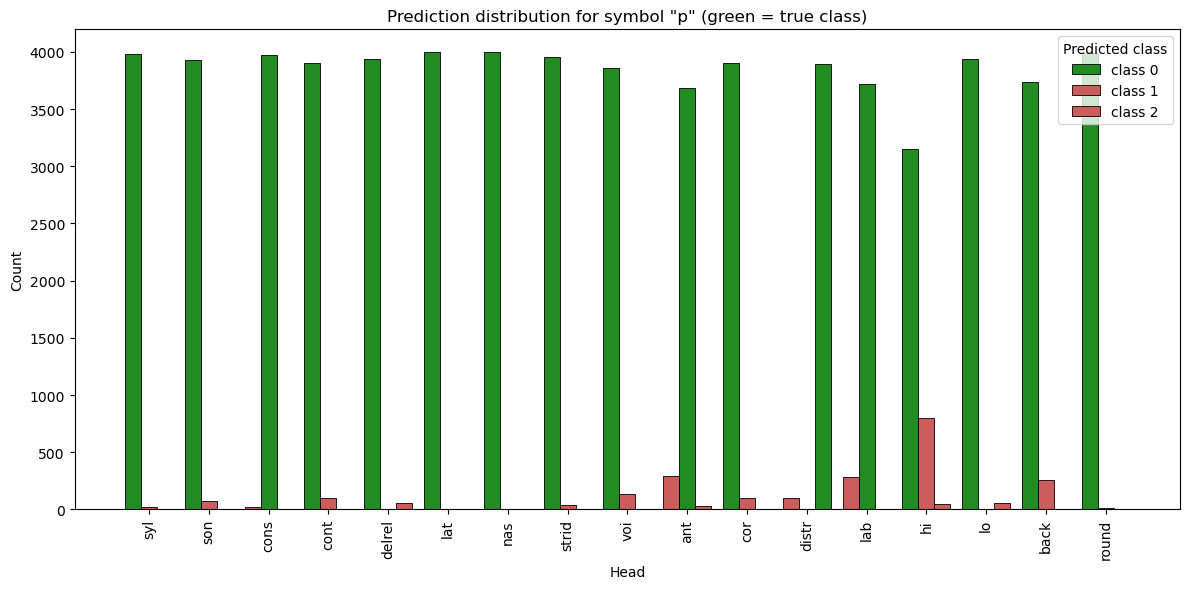

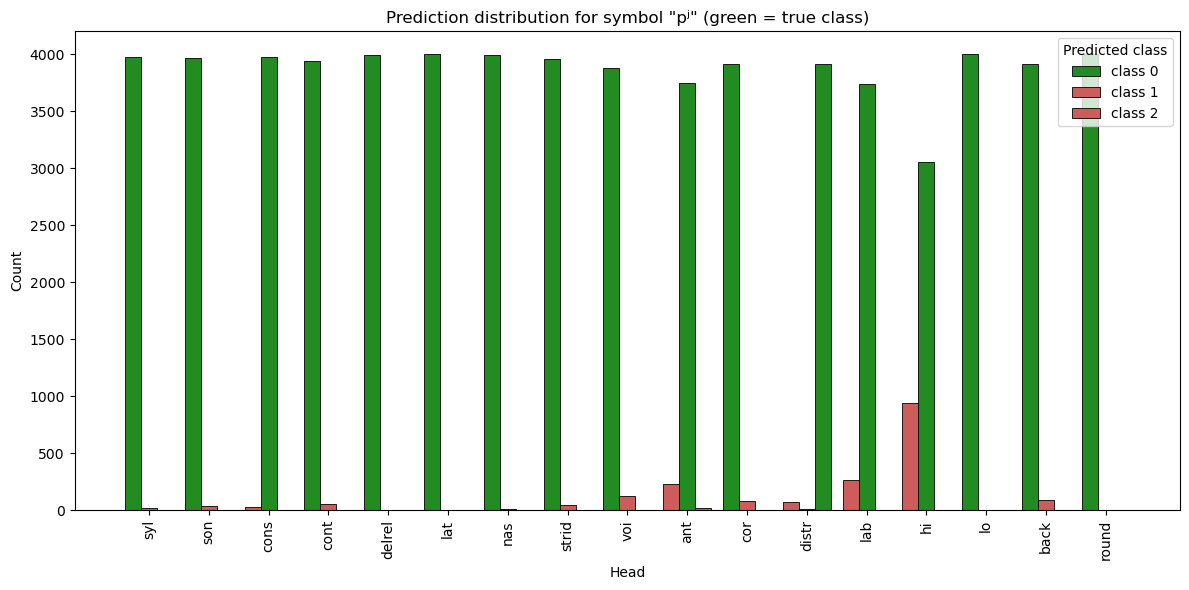

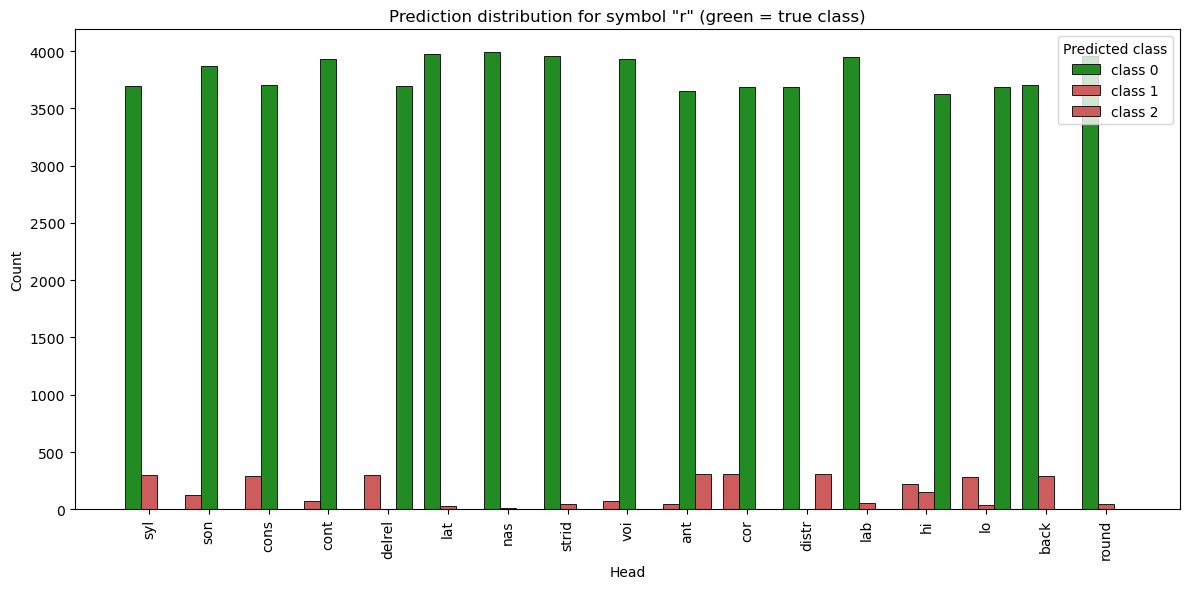

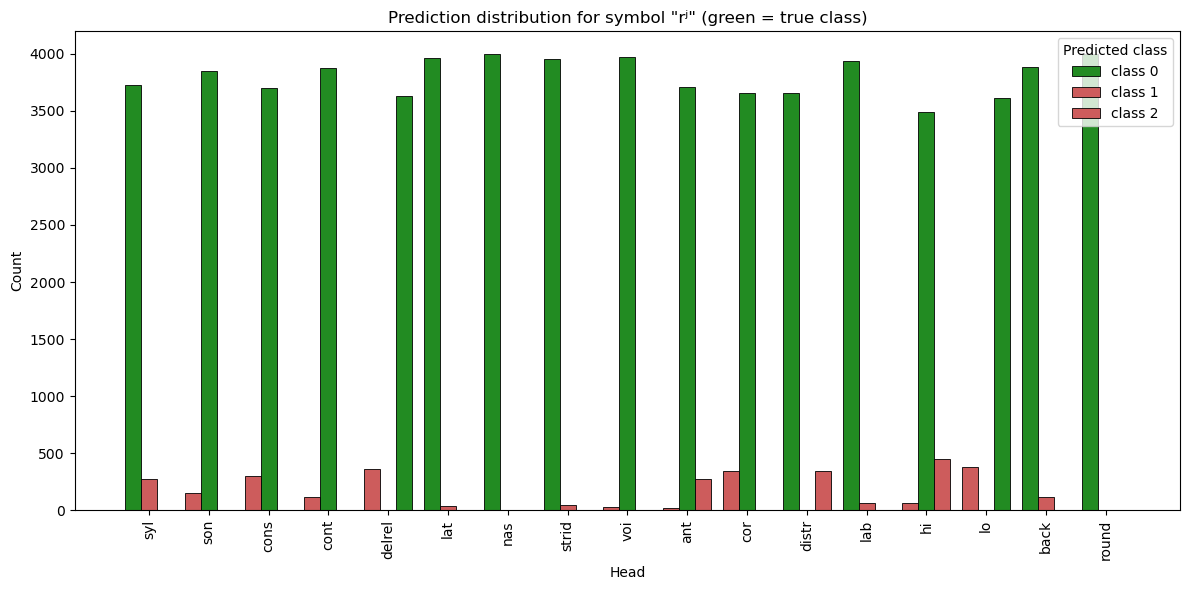

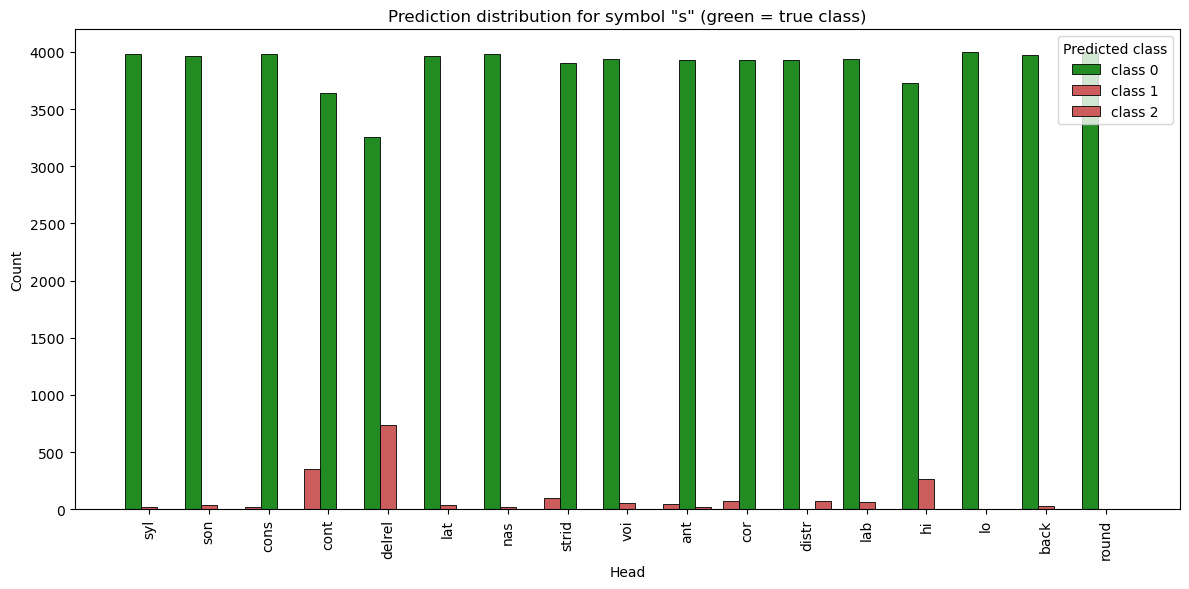

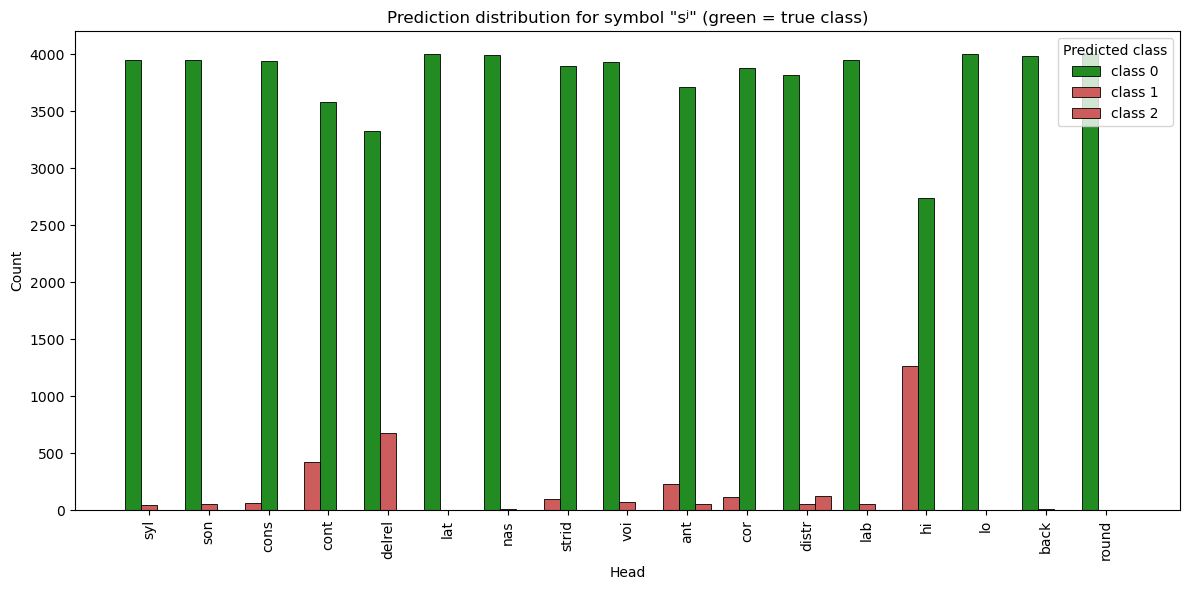

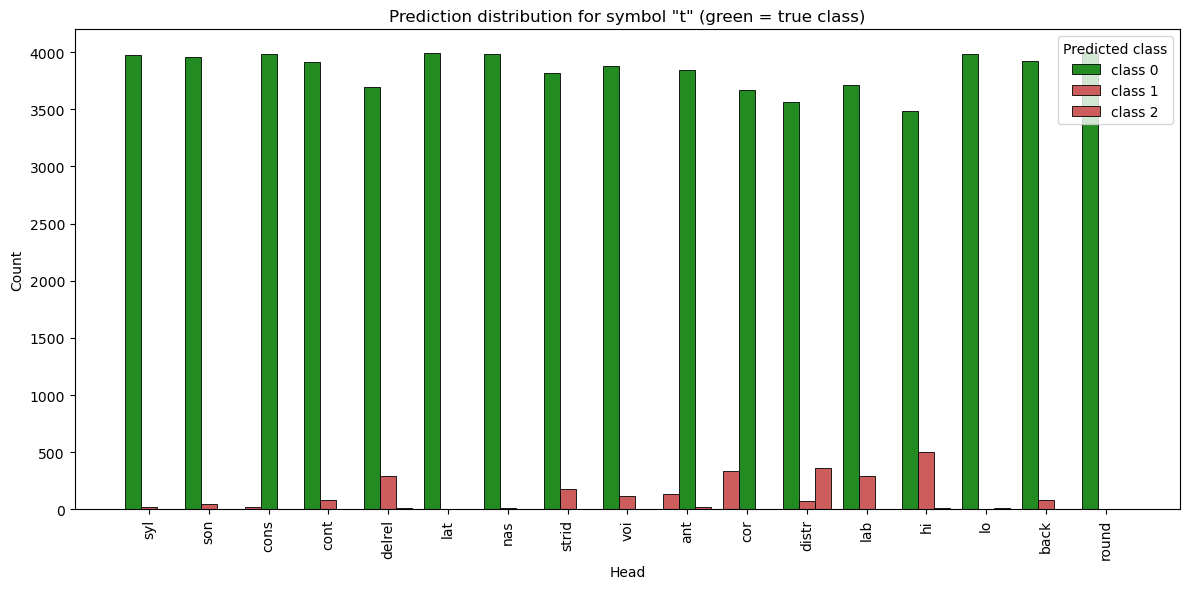

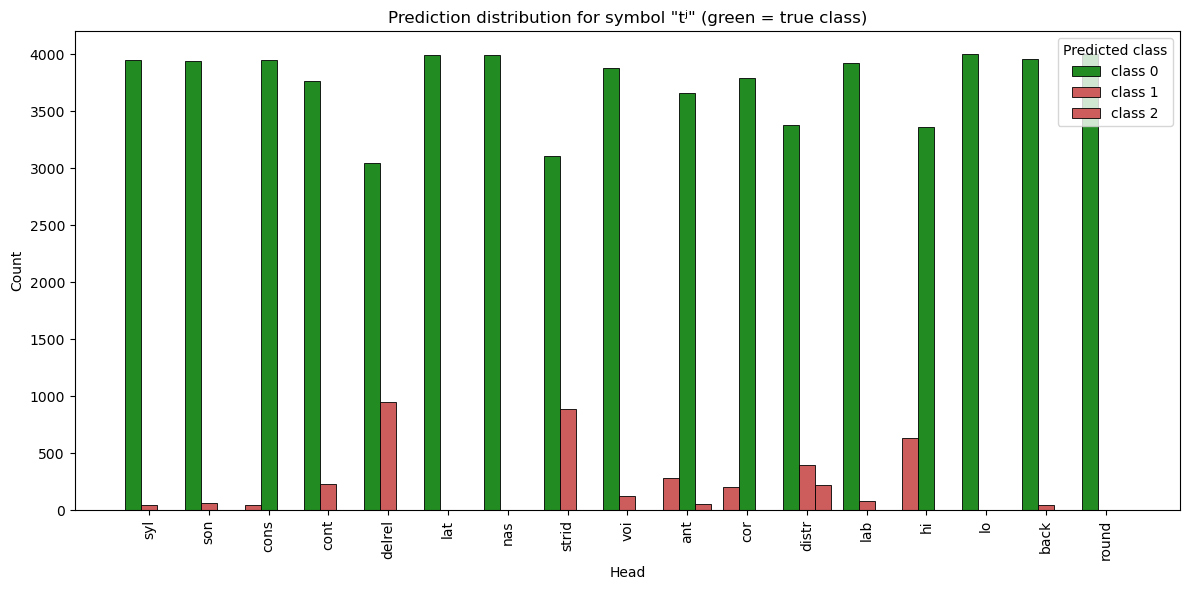

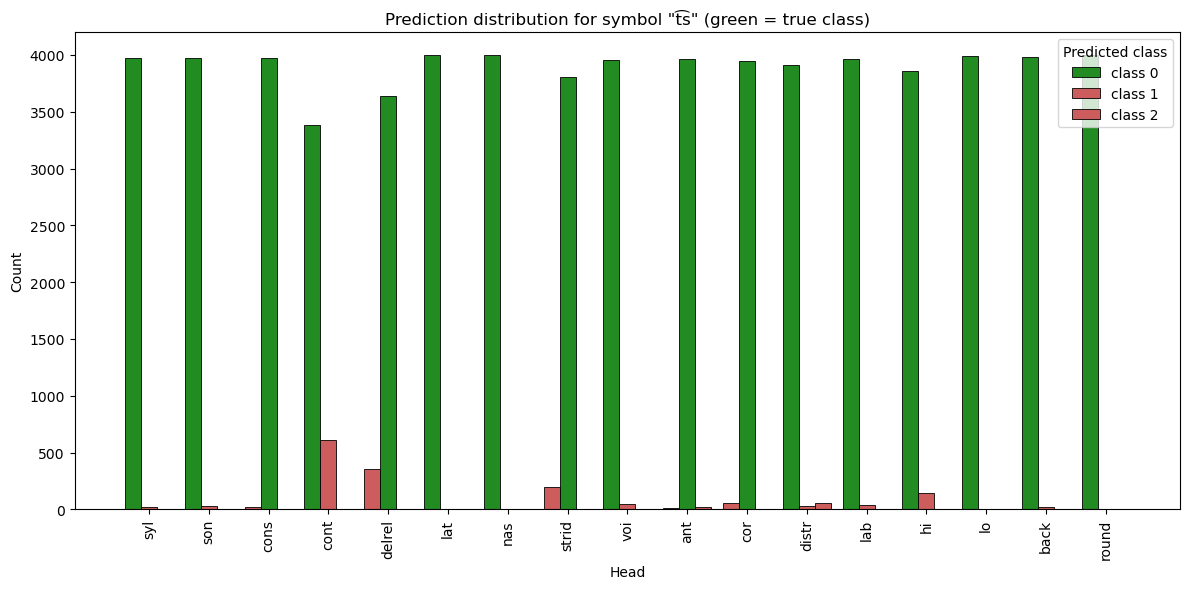

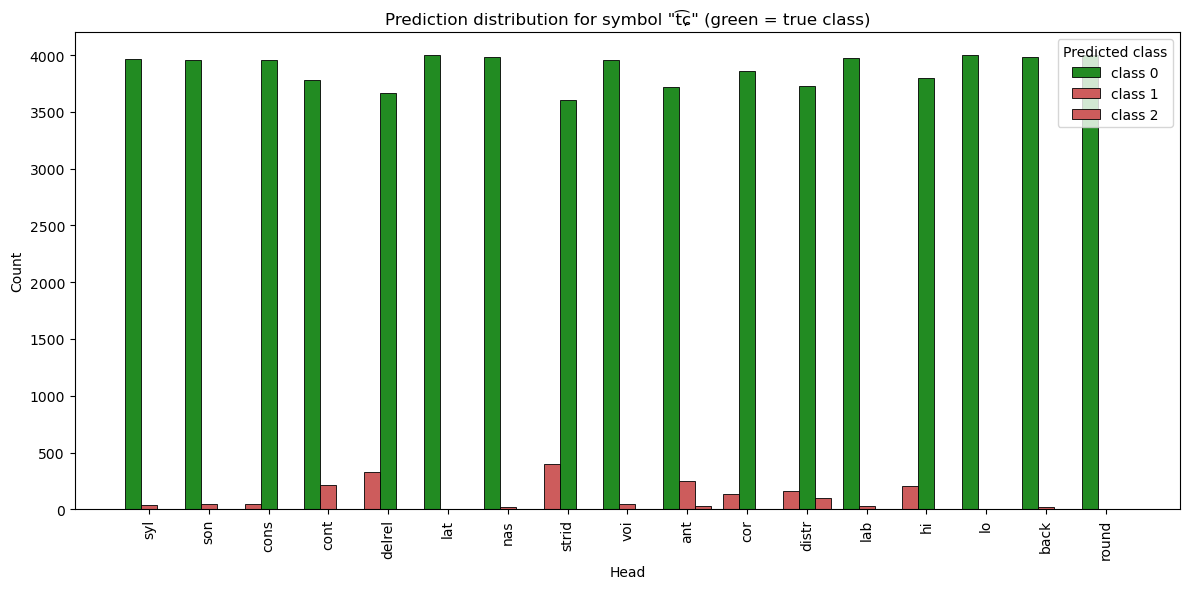

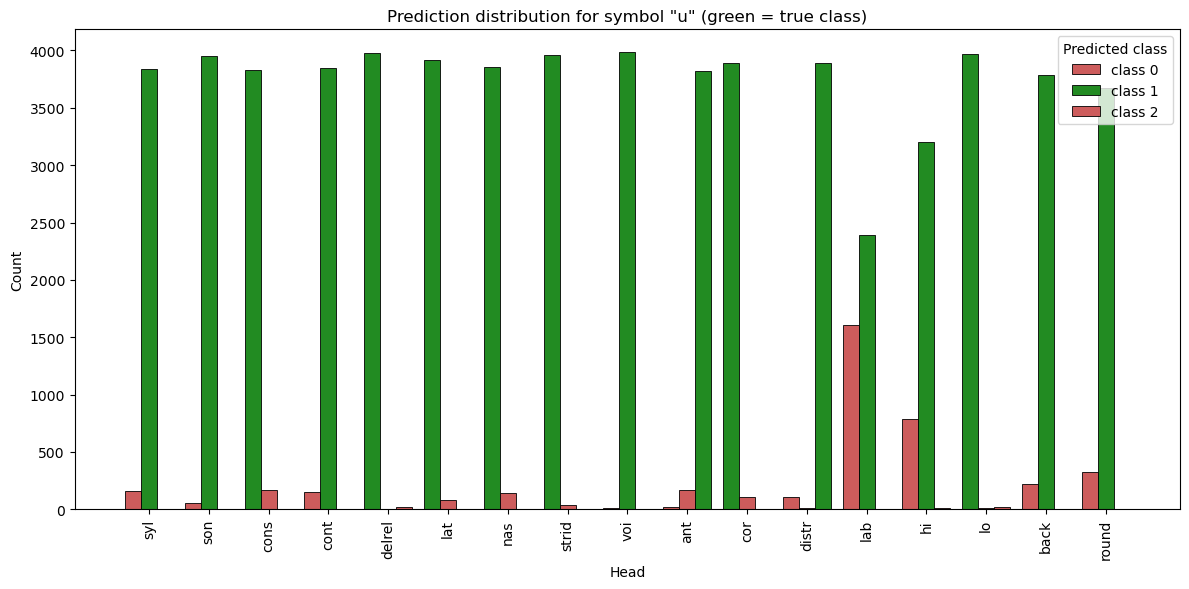

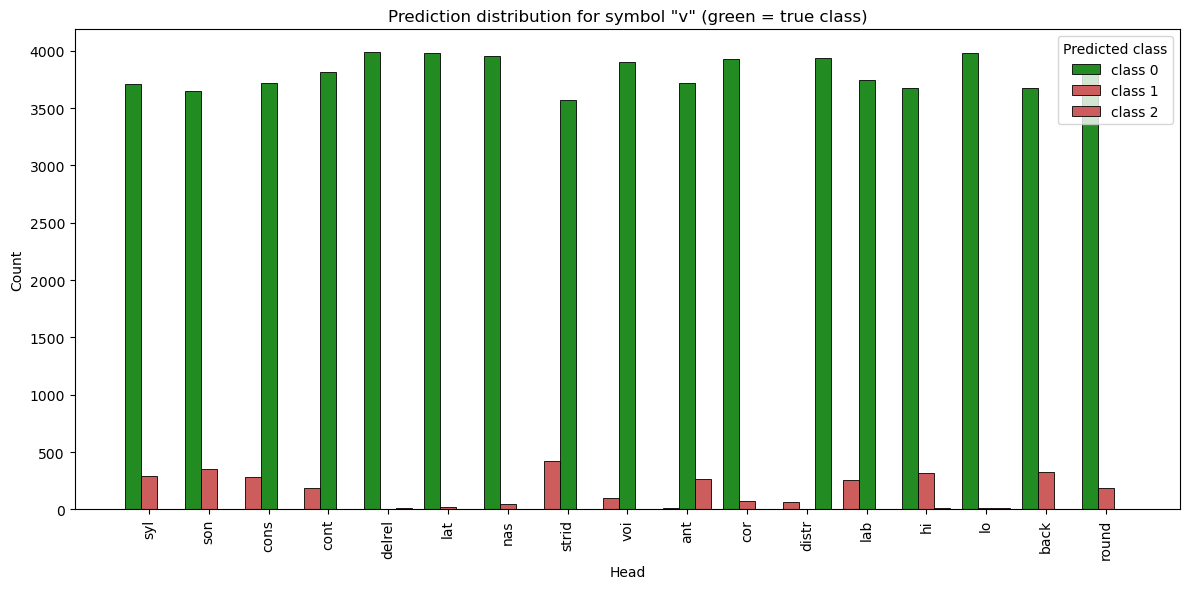

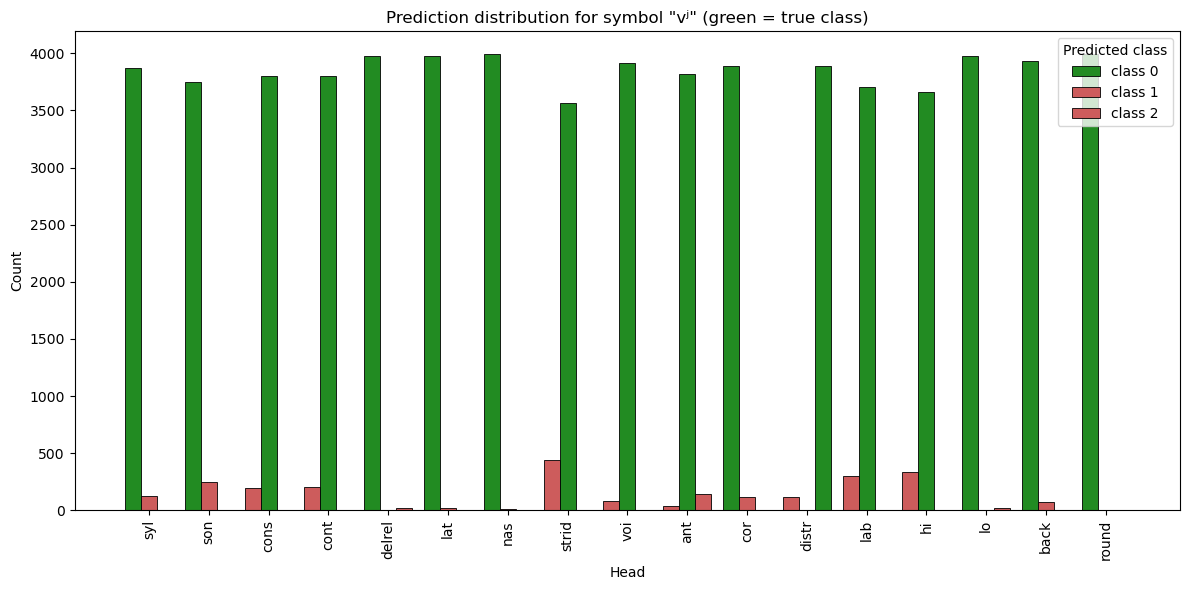

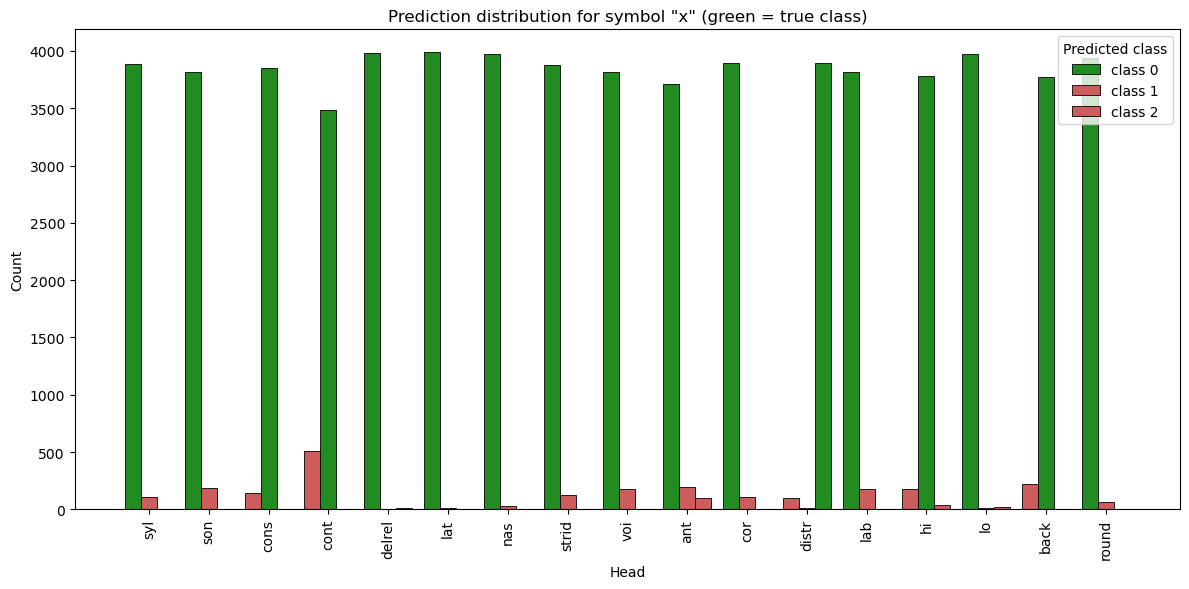

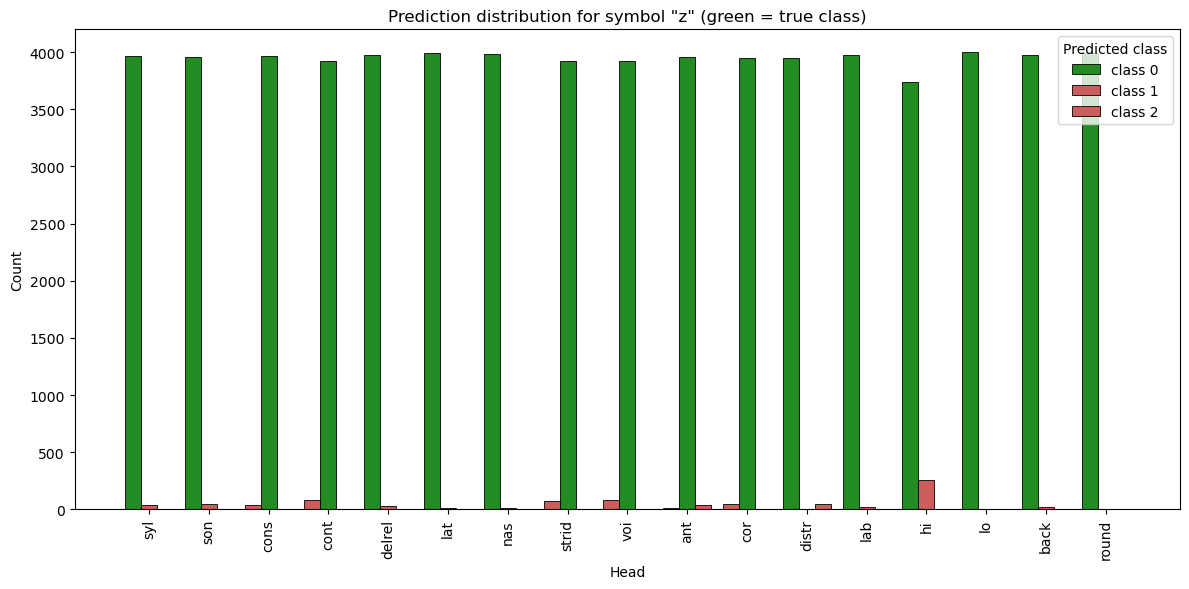

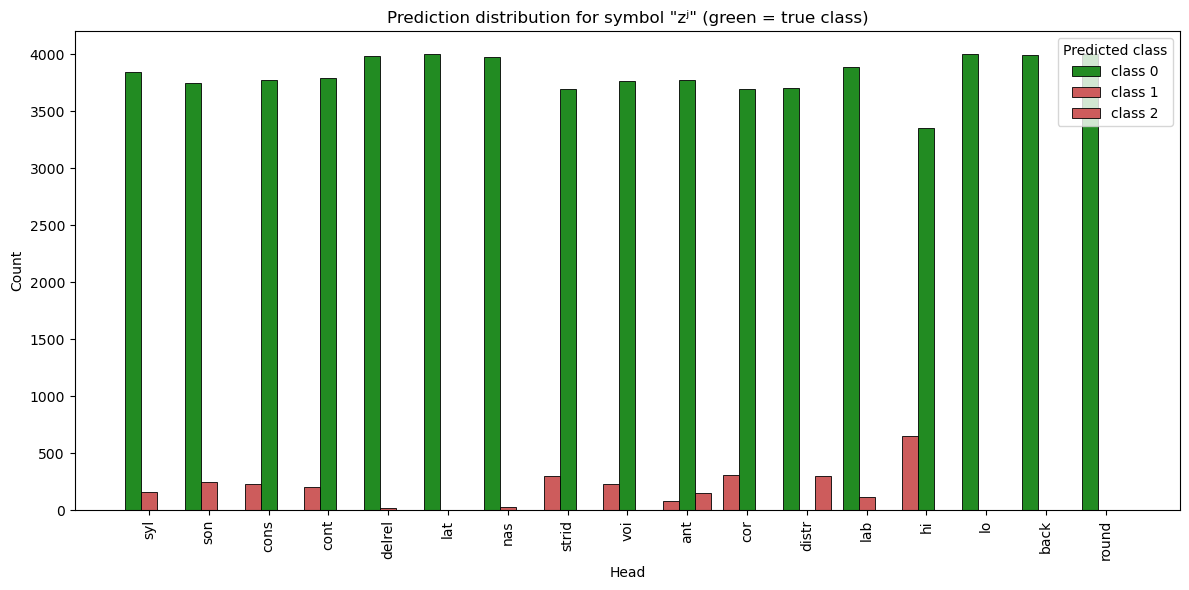

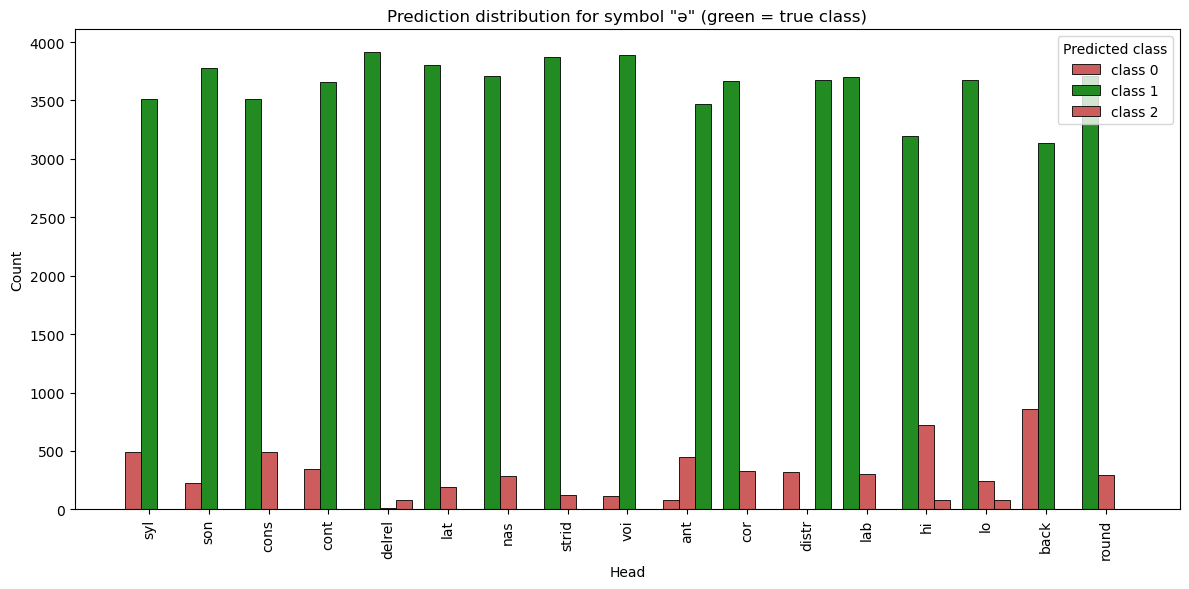

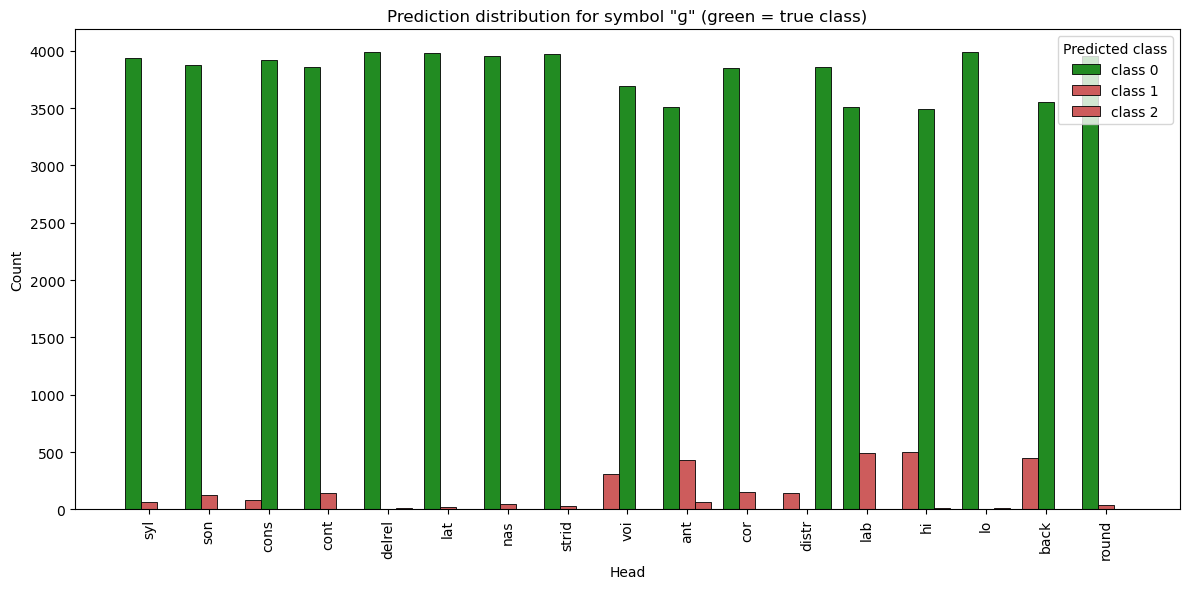

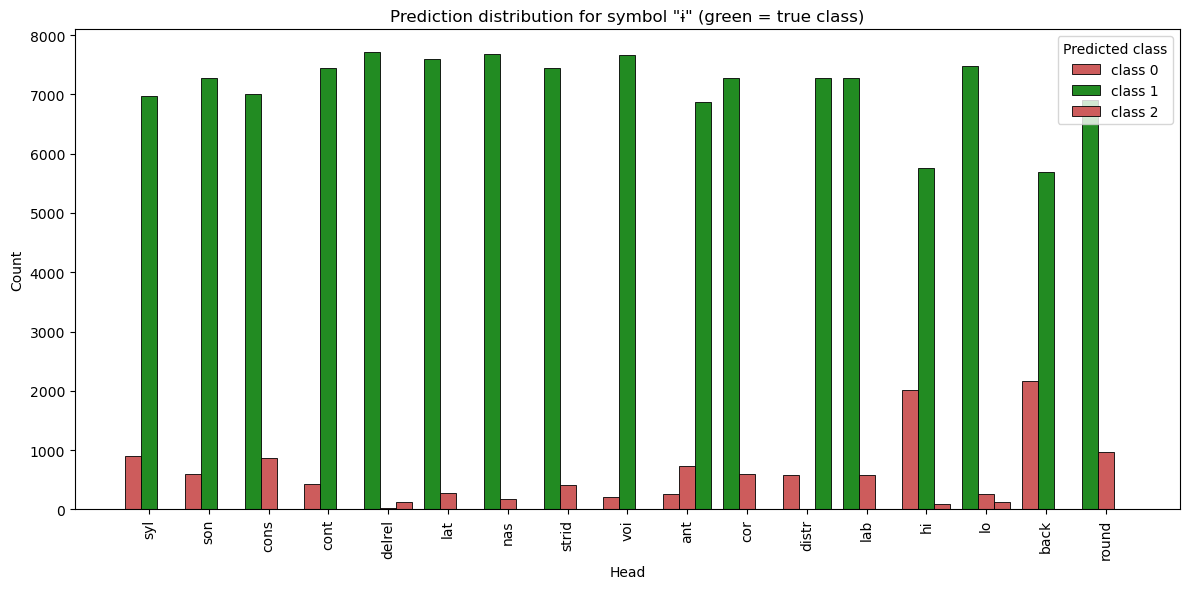

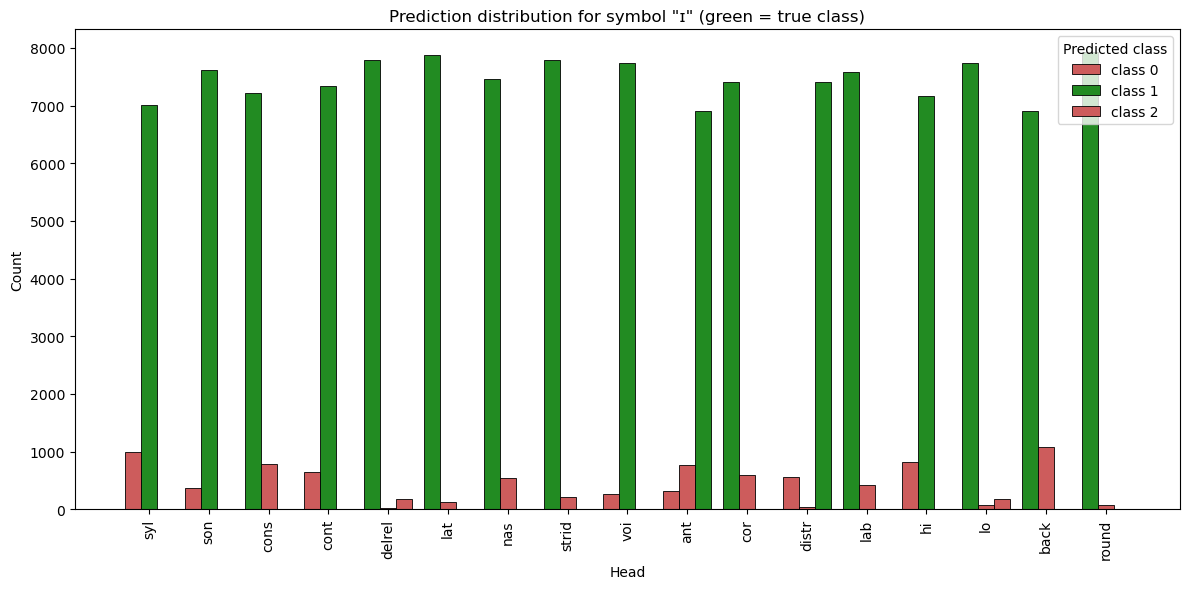

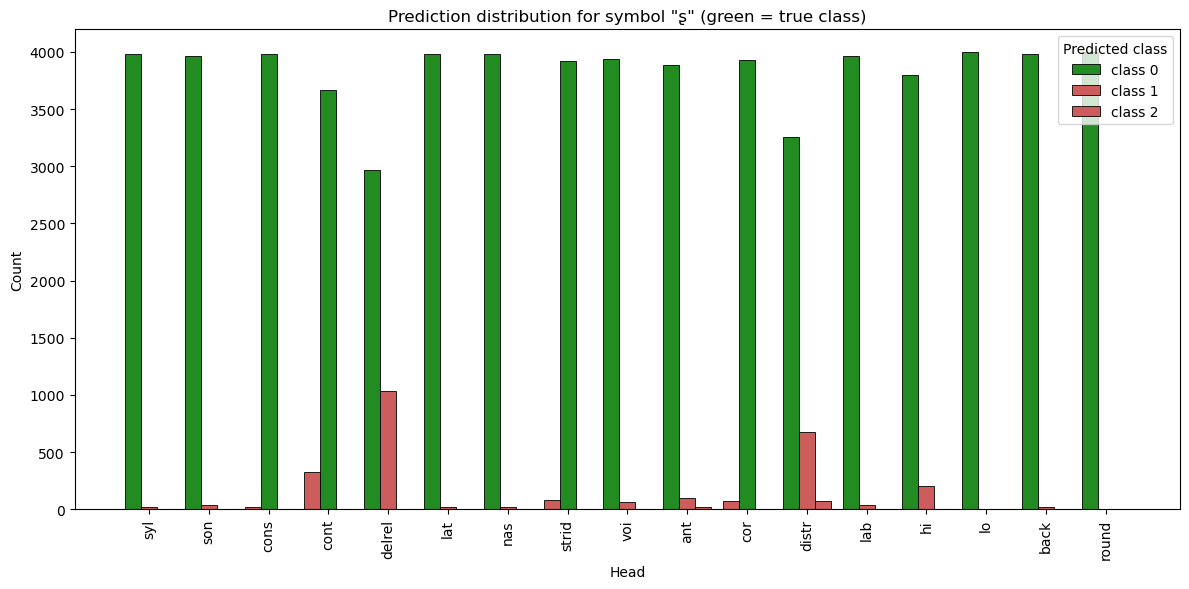

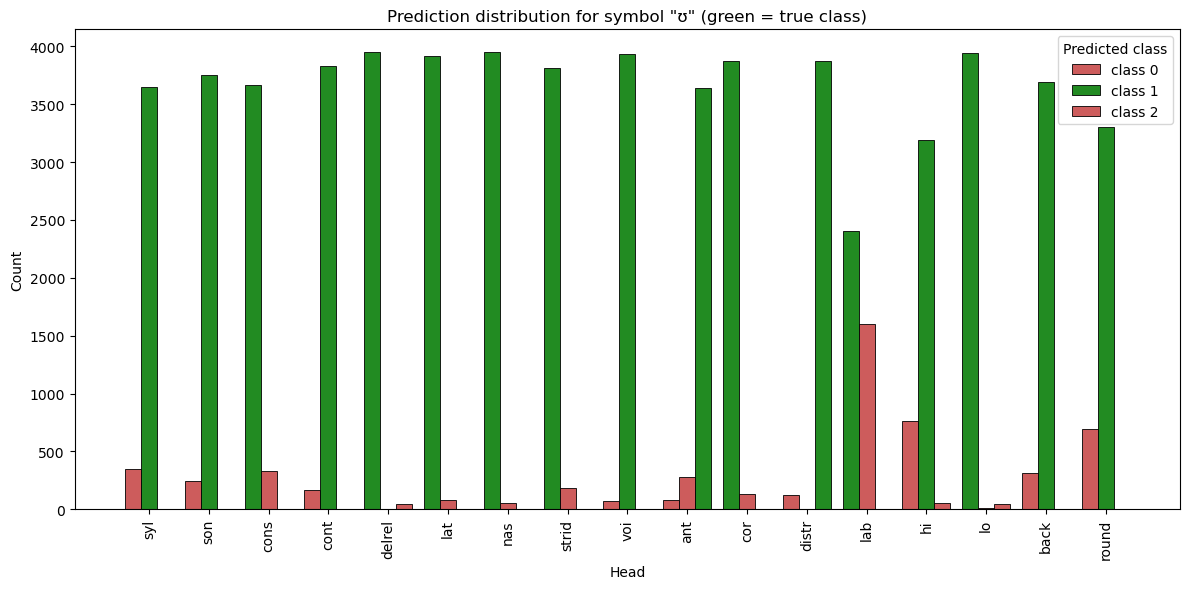

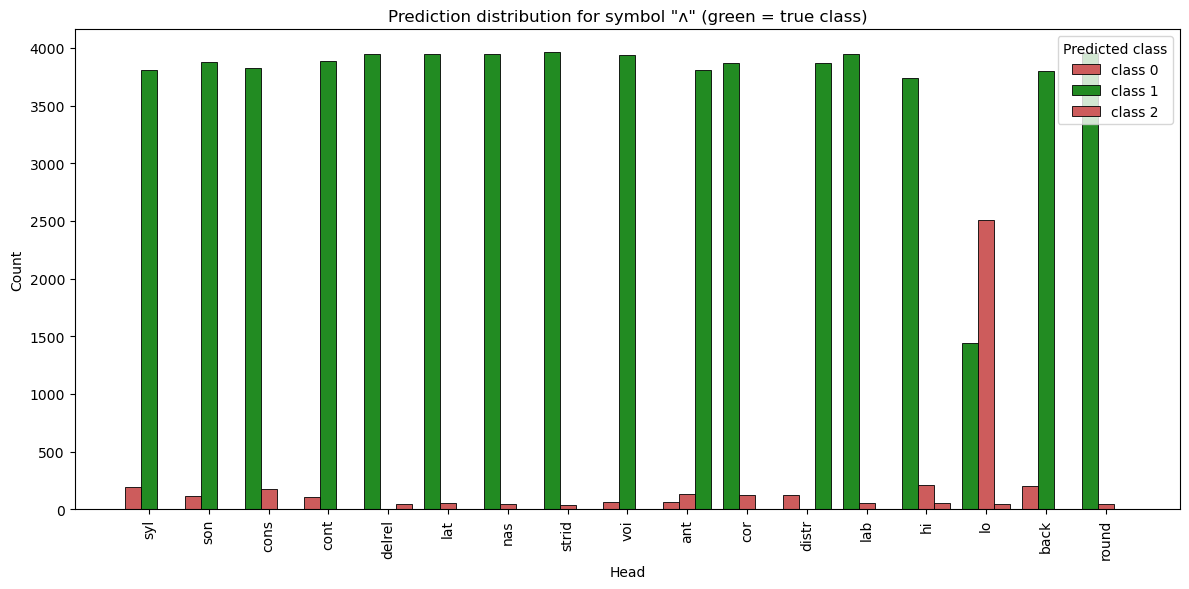

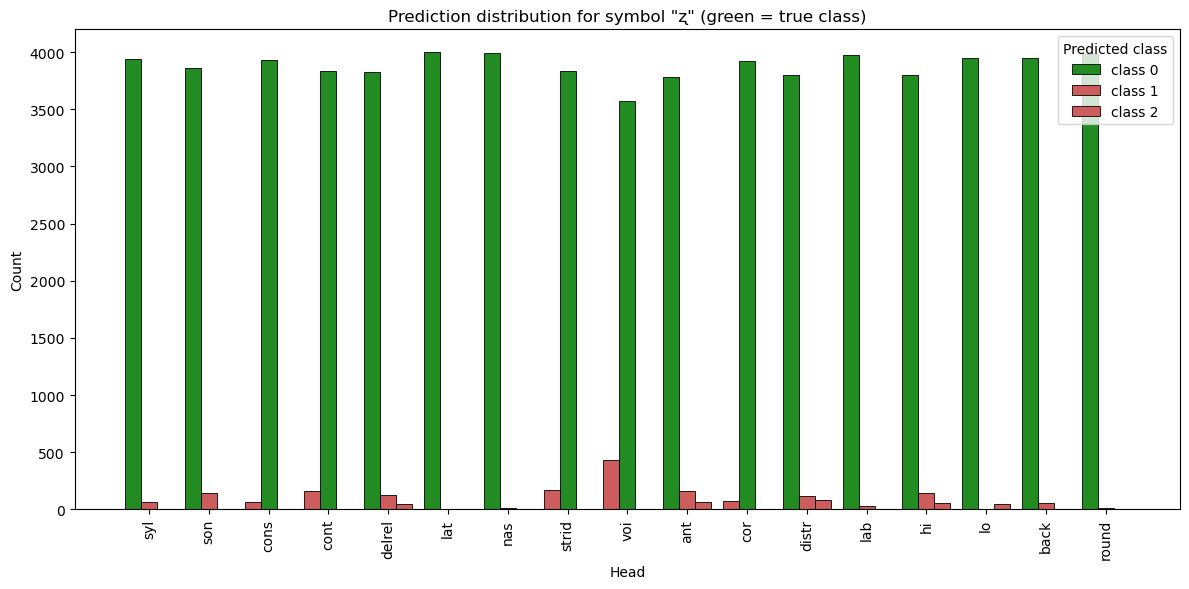

In [45]:
import pandas as pd

plot_symbol_prediction_distributions(prediction_rows, FEATURE_NAMES)


In [46]:
pd.DataFrame(prediction_rows).head()


,symbol,head,class,count,true_class
0,k,0,0,3960,0
1,k,0,1,40,0
2,k,1,0,3945,0
3,k,1,1,55,0
4,k,2,1,3958,1
